# EC data analysis with corresponding image data

This notebook plots important elecetrochemical data for CO2ELY and compares it to concurrent and potentially relevant imaging results </br>
careful: currently all Jupyter-cells of one EC-sample need to be executed to update the variables to the current sample

## TODO:
1. [ ] post-calibrate temperatue (exp.)
1. [ ] add Bernhard data as reference
1. [x]  rotate image data to be able to see membrane in-plane (write Python code, not feasible in ImageJ)
1. [x] merge all scans of sample in one .nc after rotation
1. [ ] add image observations; membrane cracking, swelling, water blockage
1. [ ] convert tomo data to densities, i.e. mA/cm2 instead of rescaling Bernahrd's data

you can write LaTeX in here :) </br>

$$E = E_0 - \frac{RT}{zF}\ln Q_r$$


In [1]:
#import relevant moduls and define general filepaths
import json
import os
import socket
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    
processing_path = os.path.join(toppath, 'processing')
path_00_4D = os.path.join(processing_path, '00_cropped_4D') #h5 with cropped data
path_01_4D = os.path.join(processing_path, '01_rotated_3p1D') #h5 with rotated data
EC_path = os.path.join(toppath, 'EC_lab_files')
overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

#go and fetch some tools from the git repo and come back
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)

import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

import pandas as pd
import scipy as sp
import scipy.interpolate

deffontsize = 10 #mpl.rcParams["font.size"]
print(deffontsize)



10


In [2]:
# some small tools

def time_fac(unit):
    if unit == 'min':
        tf = 60
    elif unit == 's':
        tf = 1
    else:
        print(unit+' unknown, assume seconds')
        tf = 1
    return tf

def get_paper_data(file):
    df = pd.read_csv(file)
    fun = sp.interpolate.interp1d((df['t [h]']-df['t [h]'][0])*3600, df[' I [mA/cm2]'], fill_value=np.nan, bounds_error=False) #converts time to s
    return fun, df

def integrate_interpolated_fun(time, fun, dts):
    integ = np.cumsum(fun(time))*dts
    return integ

In [3]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    # print(dims)
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()
    # print(len(dims))

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['Re(Z)'].data
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    # print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    # print(timestamps[0])
    
#     filter out potential overflow cases
    I = I[E>-5]
    Im = Im[E>-5]
    Re = Re[E>-5]
    timestamps = timestamps[E>-5]
    E = E[E>-5]
    
    time = timestamps - t0
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps, t0

In [4]:
#TODO: wrap into sample function, time all in min
def plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50), Atomo=0.1):

    if unit == 'min':
        tf = 60
    if unit == 's':
        tf = 1


    mpl.rcParams["font.size"] = 24
    fig, ax = plt.subplots(1,3, figsize=(35,12))
    fig.tight_layout(pad=7)
    
    ax2l = ax[0].twinx()

    #plot potential and current in left panel
    # TODO: consider multiple files with timestamps
    # for d in ECdata:
    #     d['$E_{we}$'].plot(ax=ax[0], color='k', label='$E_{we}$')
    #     d['I'].plot(ax=ax2l, color='r', label='I')
    ax[0].plot(time/tf, E,color='k', label='$E_{we}$')
    ax2l.plot(time/tf, I,color='r', label='I')
    ax[0].set_xlim(0,time.max()/tf)
    ax2l.set_xlim(0,time.max()/tf)
    ax[0].set_xlabel('time ['+unit+']')
    ax[0].set_ylabel('$E_{we}$ [V]')
    ax2l.set_ylabel('I [mA]')
    ax[0].legend(loc='lower left')
    ax2l.legend(loc='lower right')
    plt.title(sample)

    #HFR to the middle panel
    # HFR_color_plot_to_axis(ECdata[0], ax[1], fig, markersize=50, yl=(-10,40), unit='s')
    tl = (0,time.max()/tf)
    im = ax[1].scatter(Re, Im, c=time/tf, cmap = cm.viridis, marker='o', s=30, vmin=tl[0], vmax=tl[1])
    ax[1].axhline(0, color='k', linewidth=0.5)
    ax[1].set_xlim(xl[0],xl[1])
    ax[1].set_ylim(yl[0],yl[1])
    ax[1].set_xlabel('Re(Z) [$\Omega$]')
    ax[1].set_ylabel('-Im(Z) [$\Omega$]')

    divider = make_axes_locatable(ax[1])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical', label='time ['+unit+']')

    # power vs charge
    ax[2].plot(Q/1000/Atomo, E*I/Atomo)
    ax[2].set_xlabel('charge [$As\cdot cm^{-2}$]')
    ax[2].set_ylabel('power density [$mW\cdot cm^{-2}$]')
    ax[2].set_xlim(0,Q.max()/1000/Atomo)



In [21]:
def plot_EC_with_annot(sample, unit = 'min',y_txt_frac = 8/8,y_txt_scan = 1/20, tl=None, Atomo=0.1):
    
    tf = time_fac(unit)

    #plot the echem data 
    fig, ax = plt.subplots(figsize=(40,12))
    if tl is not None:
        ax.set_xlim(tl[0],tl[1])
    plt.title(sample)
    ax.plot(time/tf, E, 'k', label='$E_{we}$')
    ax2 = ax.twinx()
    ax2.plot(time/tf, -I/Atomo, 'r', label='J')
    ax.legend(loc='lower left')
    ax2.legend(loc='lower right')
    ax.set_xlabel('time ['+unit+']')
    ax.set_ylabel('$E_{we}$ [V]')
    ax2.set_ylabel('-J [$mA\cdot cm^{-2}$]')

    # mark the gas cues TODO: somehow does not catch all cues, maybe isue with t0?
    rel_cues = np.array(overview['cues']['timestamp'].copy())
    comms = np.array(overview['cues']['comment'].copy())
    comms = comms[rel_cues>t0]
    rel_cues = rel_cues[rel_cues>t0]
    comms = comms[rel_cues<t0+time.max()]
    rel_cues = rel_cues[rel_cues<t0+time.max()]
    rel_cues = rel_cues-t0

    text_y = I.max()+(I.min()-I.max())*y_txt_frac
    if len(rel_cues)>0:
        for (cue, comm) in zip(rel_cues,comms):
            ax.axvline(cue/tf)
            plt.annotate(comm, xy=(cue/tf, text_y), rotation=90)

    #mark the scan time steps
    scan_steps = []
    check = sample
    if sample == '3II':
        check = '3b'

    text_2 = I.max()+(I.min()-I.max())*y_txt_scan   
    # old annotation position and font with 00_cropped_4D
    # for file in os.listdir(path_00_4D):
    #     if file.split('_')[2] == sample or file.split('_')[2] == check:
    #         data = xr.open_dataset(os.path.join(path_00_4D, file))
    #         scan_nr = data.attrs['scan_#']
    #         steps = data['t_utc'].data-t0
    #         steps.sort()
    #         for (i,ts) in zip( range(len(data['t_utc'])),steps):
    #             if i == 0:
    #                 plt.annotate(scan_nr, xy=(ts/tf, I.max()))
    #             ax.axvline(ts/tf, color='k', alpha=0.75)
    #             plt.annotate(str(i), xy=(ts/tf, text_2), fontsize=15)
    #         data.close()
    for file in os.listdir(path_01_4D):
        if file.split('_')[1] == sample:
            data = xr.open_dataset(os.path.join(path_01_4D, file))
            steps = data['t_utc'].data#-t0
            for (i,ts) in zip( range(len(data['t_utc'])),steps):
                ax.axvline(ts/tf, color='k', alpha=0.75)
                plt.annotate(str(i), xy=(ts/tf, -text_2/Atomo), fontsize=15)
            data.close()
        

## Literature reference

### "Bernhard" paper
Pribyl-Kranewitter, B., A. Beard, T. Schuler, N. Diklić and T. J. Schmidt (2021). "Investigation and Optimisation of Operating Conditions for Low-Temperature CO2 Reduction to CO in a Forward-Bias Bipolar-Membrane Electrolyser." Journal of The Electrochemical Society 168(4).

Data extracted from Figure 8 with WebPlotDigitizer (https://apps.automeris.io/wpd/)

In [6]:
folder = os.path.join(gitpath, 'meta_and_linking_data','Bernhard_Paper_extracted_data_figure_8')

# TODO: plot various relations, i.e. I vs t, power vs t, norm I vs charge, I vs charge power vs charge

dt = 0.025 # h
dts = dt*3600
time = np.arange(0,12,dt)*3600
NA = 6.0221415E23 #mol
A = 4 #cm2, acitve area of Bernhard
Atomo = 0.1 #cm2 approximate active area of the tomocell
Arescale = Atomo/A
bern_data = {}

for file in os.listdir(folder):
    fun, df = get_paper_data(os.path.join(folder, file)) #current density in mA/cm2
    current = fun(time)
    integ = integrate_interpolated_fun(time, fun, dts)/1000 #convert mAs to As
    bern_data[file[:-7]] = {'scaled current [mA]': current*Atomo, 'current density [mA/cm2]': current, 'charge density[As/cm2]': integ, 'charge [As]': integ*A, 'rescaled charge [As]': integ*Atomo}

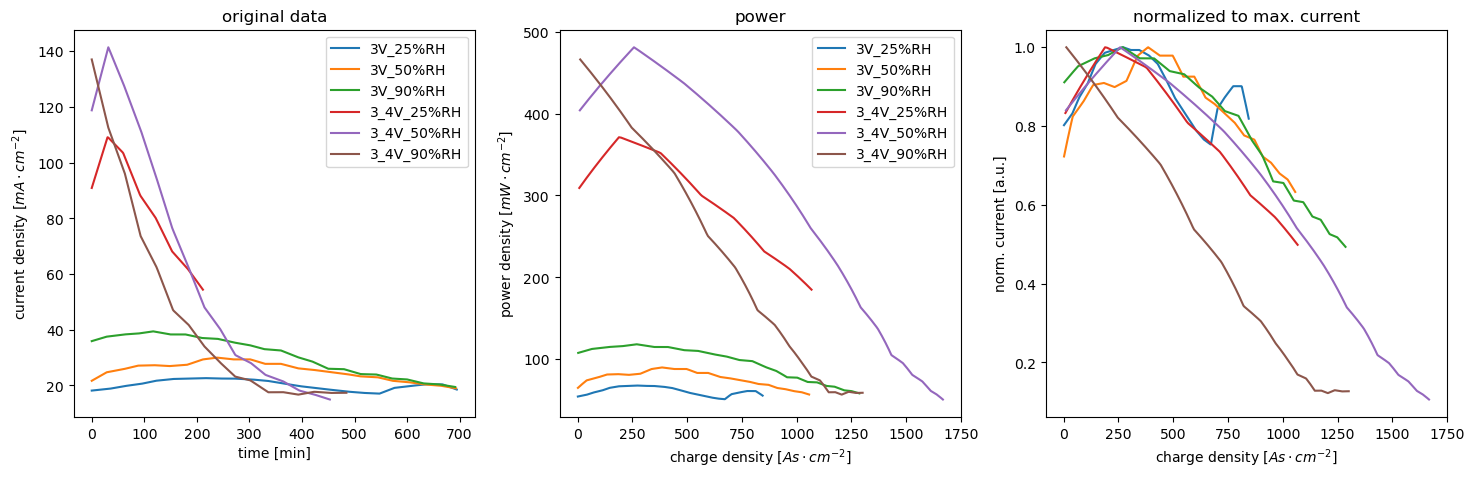

In [7]:
fig, axs = plt.subplots(1,3, figsize=(15,5))
fig.tight_layout(pad=3)
unit = 'min'
if unit == 'min': tf = 60

for pot in bern_data.keys():
    axs[0].plot(time/tf, bern_data[pot]['current density [mA/cm2]'], label = pot+'RH')
    axs[0].set_xlabel('time ['+unit+']')
    axs[0].set_ylabel('current density [$mA\cdot cm^{-2}$]')
    axs[0].legend()
    axs[0].set_title('original data')
    
    if pot[1] == 'V':
        E = 3
    else:
        E = 3.4
    
    axs[1].plot(bern_data[pot]['charge density[As/cm2]'], bern_data[pot]['current density [mA/cm2]']*E, label = pot+'RH')
    axs[1].set_xlabel('charge density [$As\cdot cm^{-2}$]')
    axs[1].set_ylabel('power density [$mW\cdot cm^{-2}$]')
    axs[1].legend()
    axs[1].set_title('power')
    
    axs[2].plot(bern_data[pot]['charge density[As/cm2]'], bern_data[pot]['current density [mA/cm2]']/np.nanmax(bern_data[pot]['current density [mA/cm2]']), label = pot+'RH')
    # axs[1].legend()
    axs[2].set_title('normalized to max. current')
    axs[2].set_xlabel('charge density [$As\cdot cm^{-2}$]')
    axs[2].set_ylabel('norm. current [a.u.]')
    
    # axs[1].plot(time/tf, bern_data[pot]['current density [mA/cm2]']*E, label = pot+'RH')
    # axs[1].set_xlabel('time ['+unit+']')
    # axs[1].set_ylabel('power density [mW/cm2]')
    # axs[1].legend()
    # axs[1].set_title('power')

In [8]:
# global variables and dicts
charge_dict = {}

## Cell 4 (Sample 4)

### short description

Galvanostatic operation 3mA<br />

In [9]:
sample = '4'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

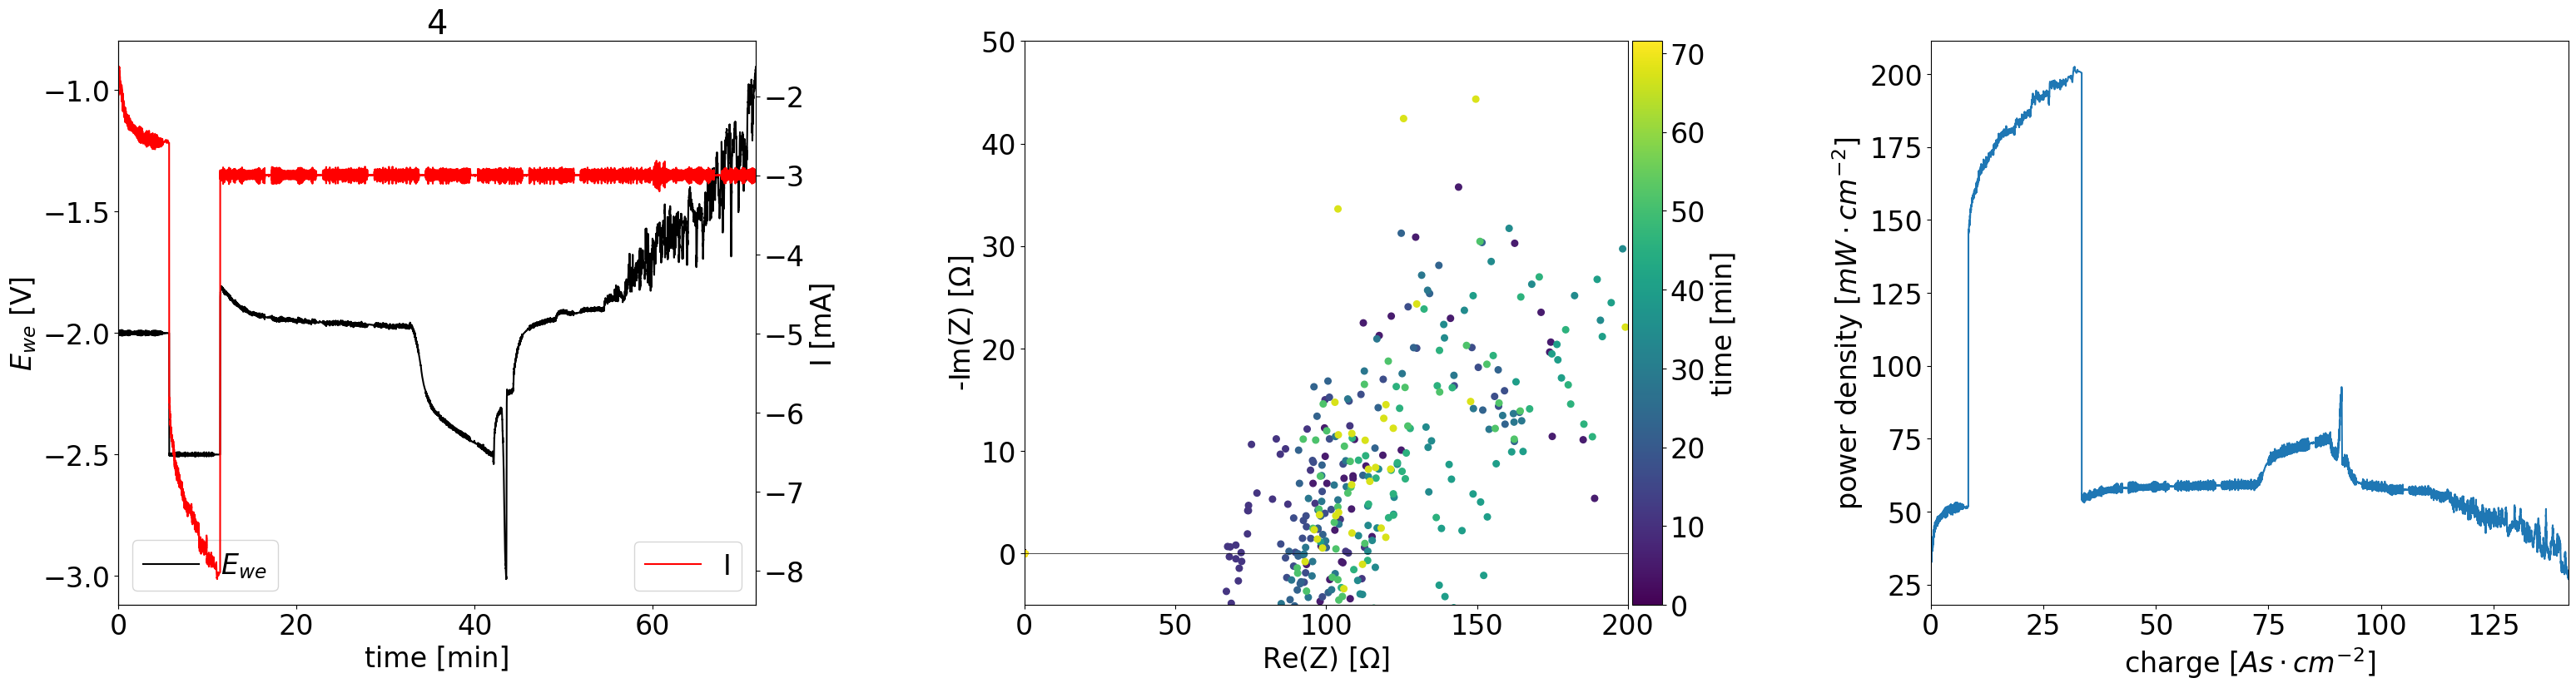

In [10]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

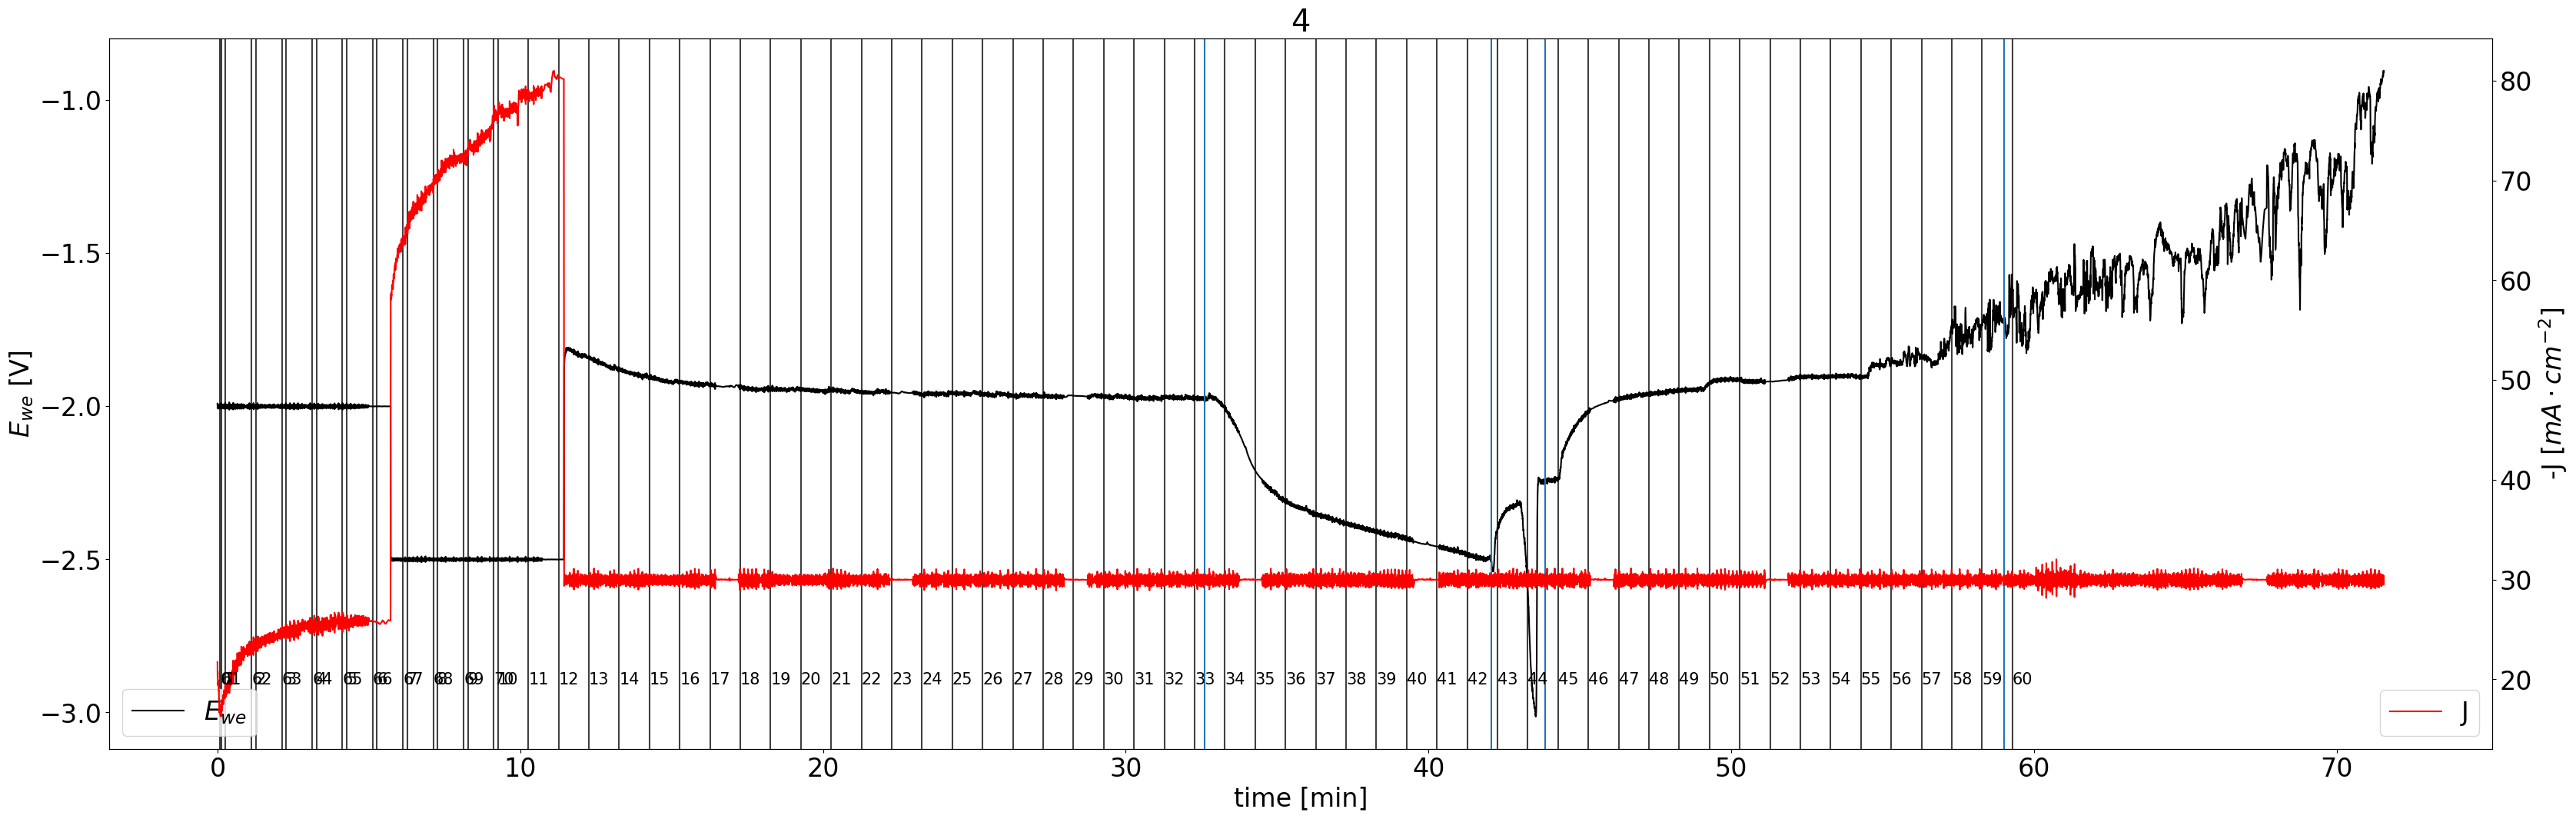

In [22]:
plot_EC_with_annot(sample)

## Cell 5

### short description

Galvanostatic operation 10mA and 15mA <br />

In [10]:
sample = '5'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

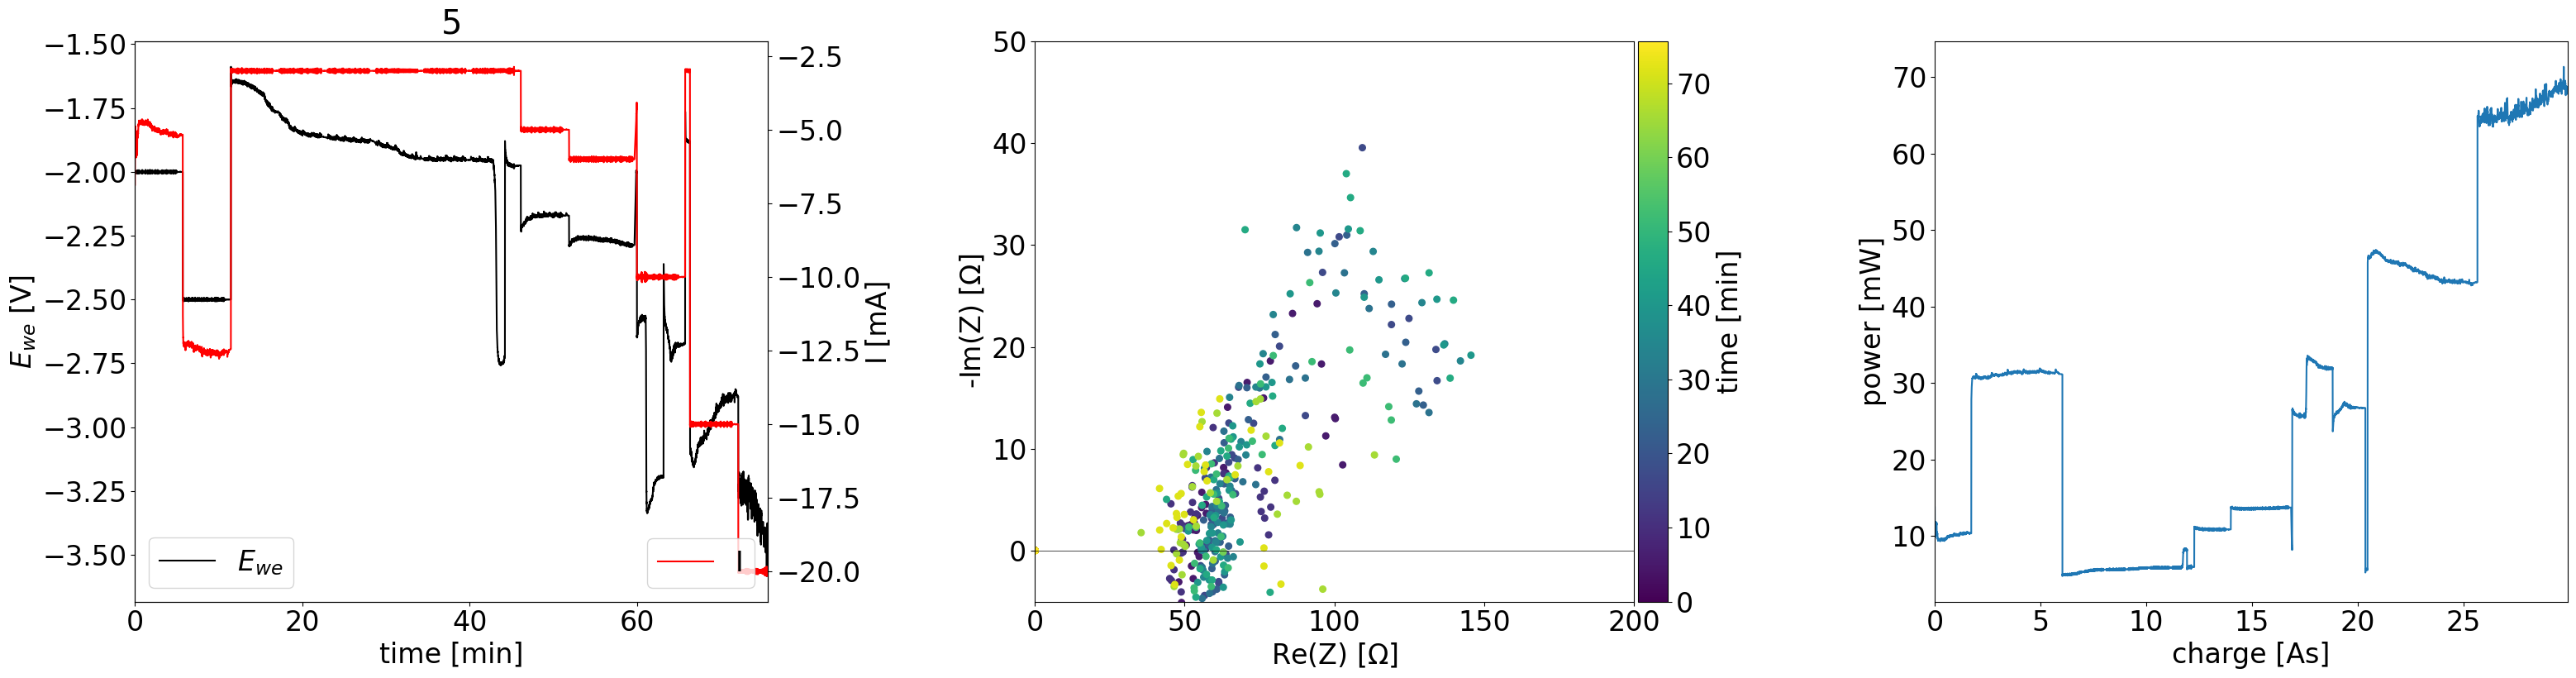

In [11]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

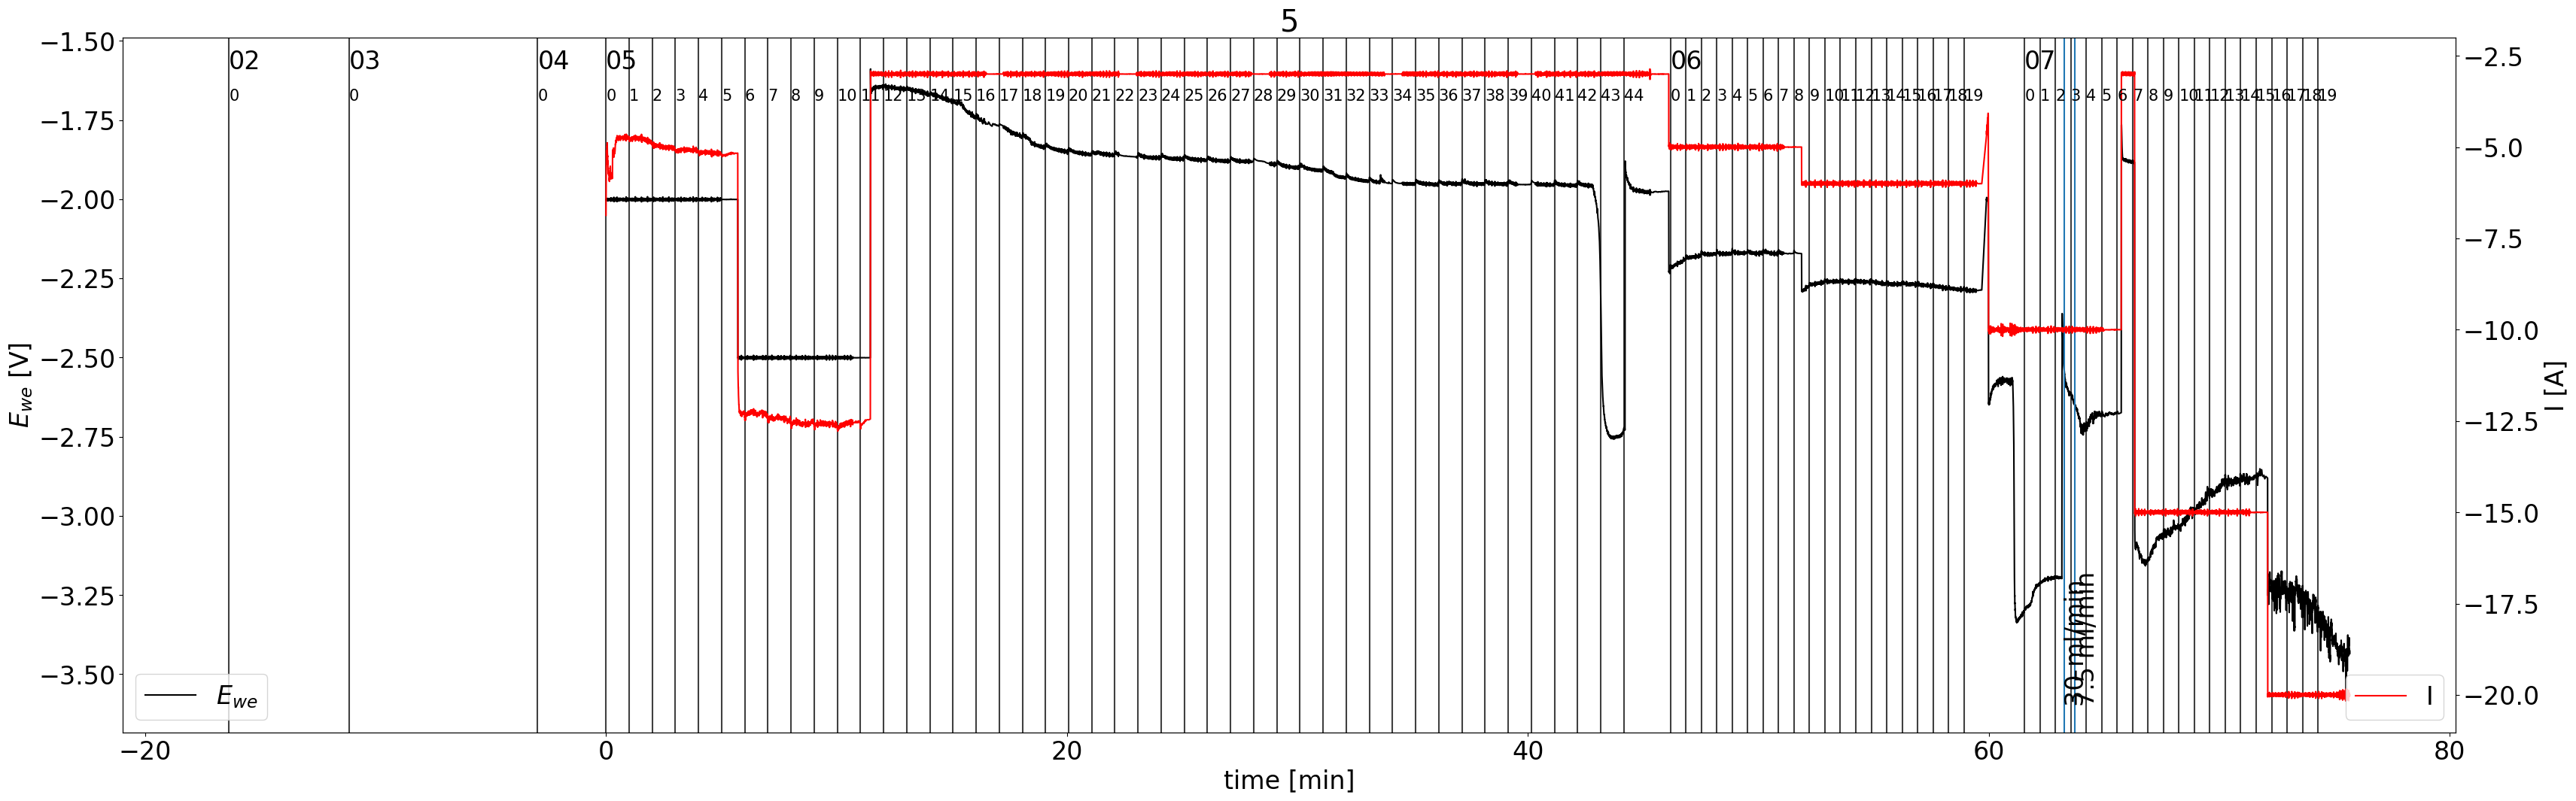

In [12]:
plot_EC_with_annot(sample)

## Cell 6

### short description

Galvanostatic operation 5mA<br />

In [13]:
# load data TODO wrap into function and provided small dossier as dict
sample = '6'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

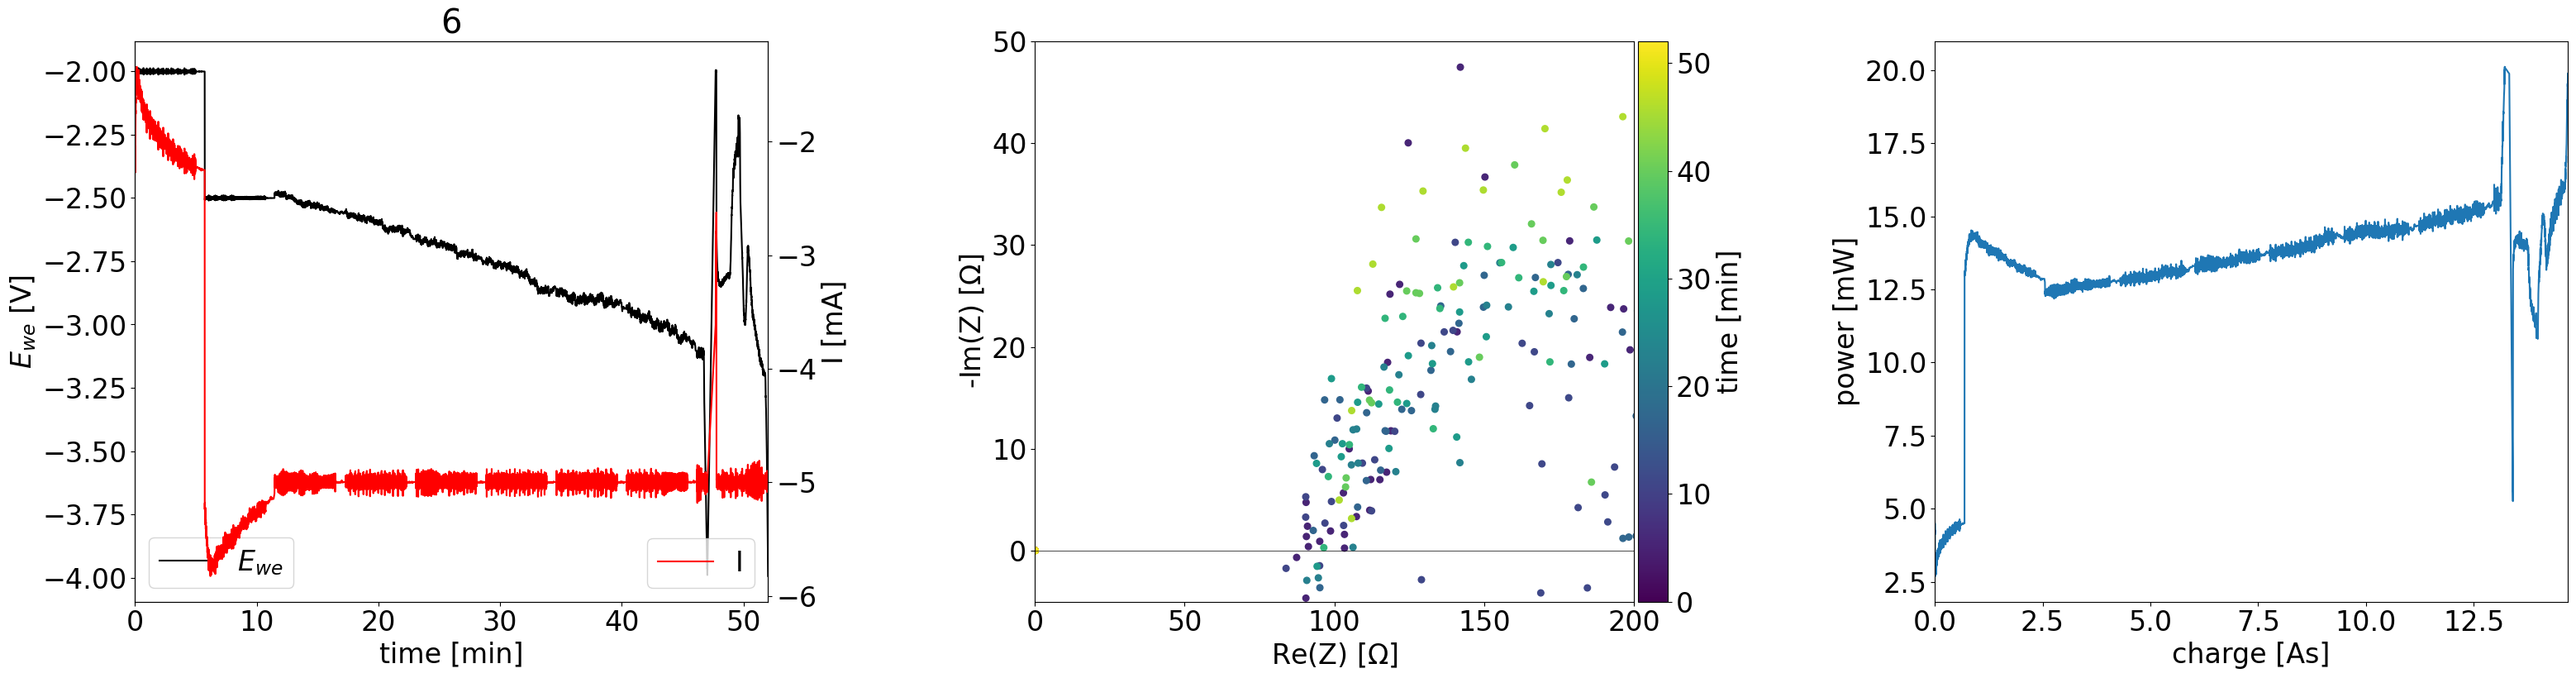

In [14]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

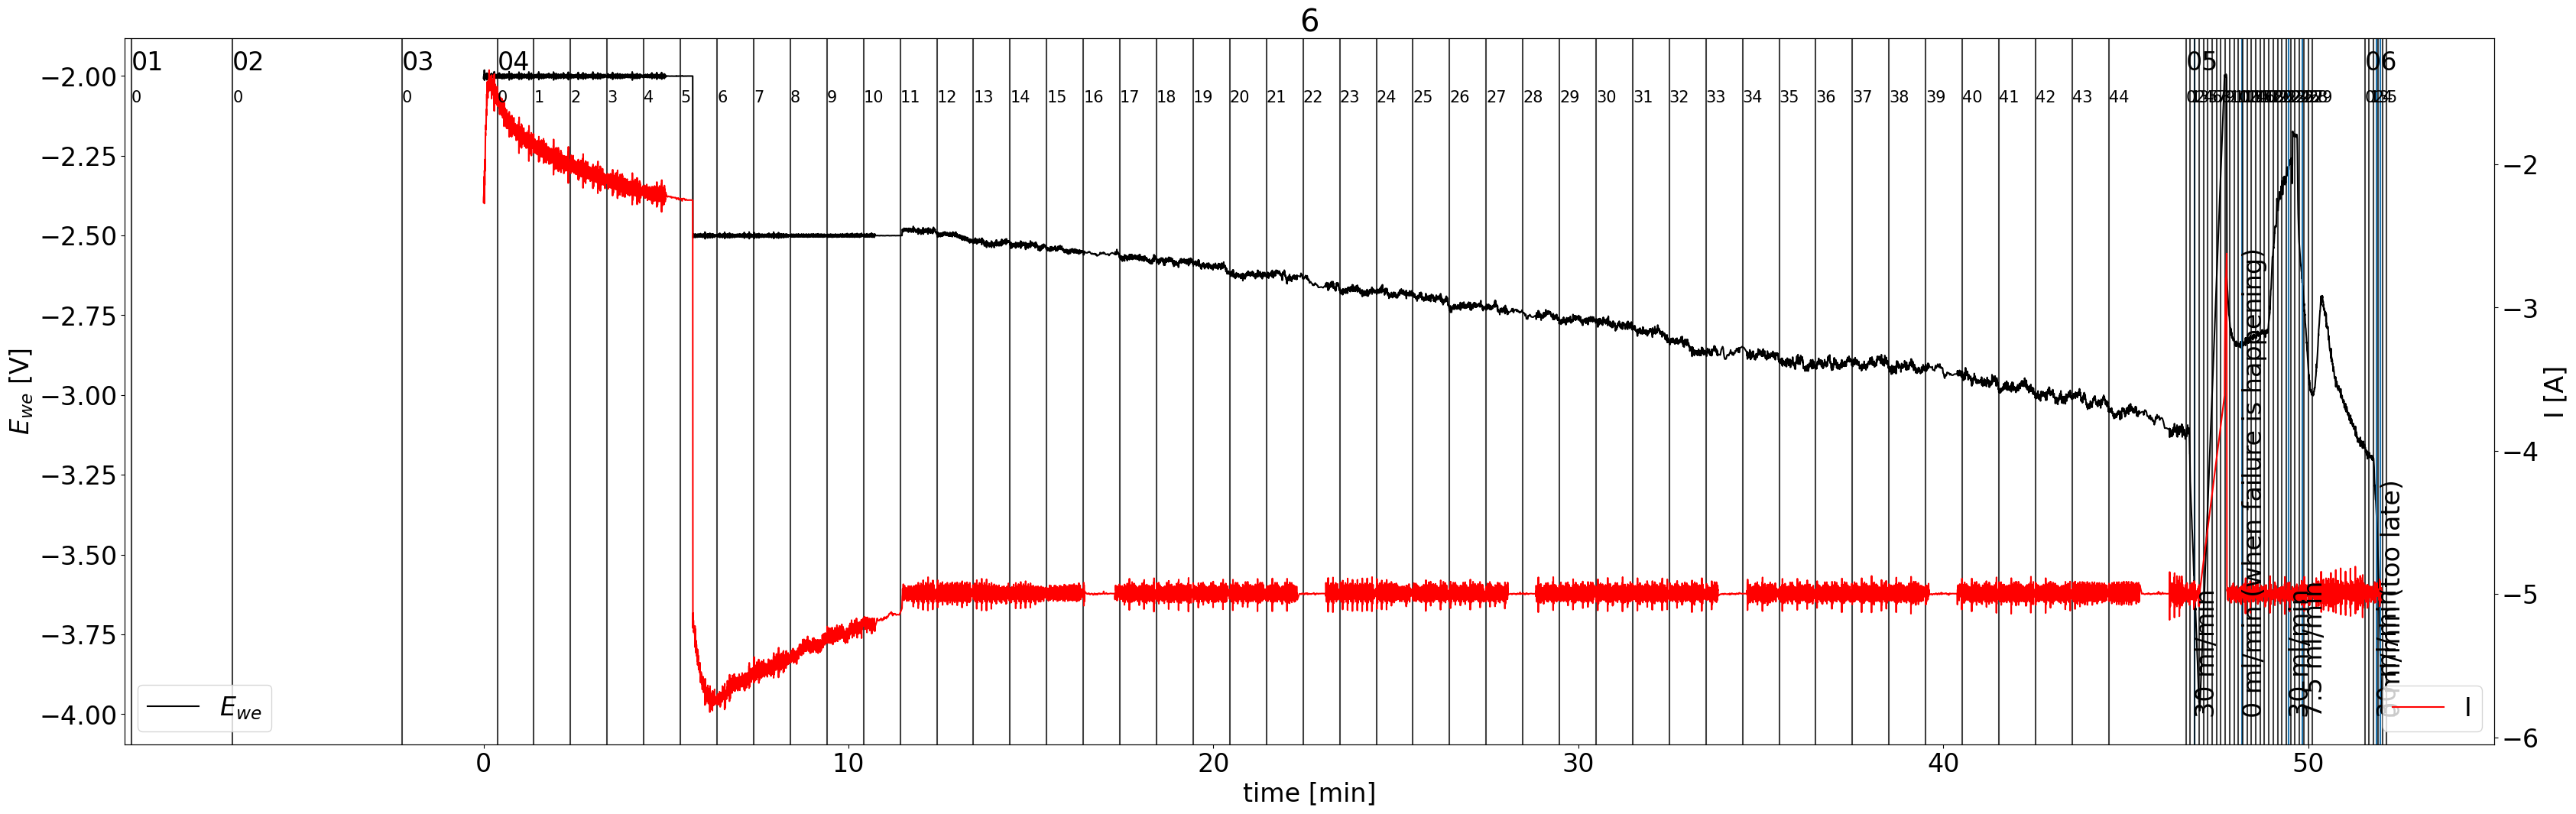

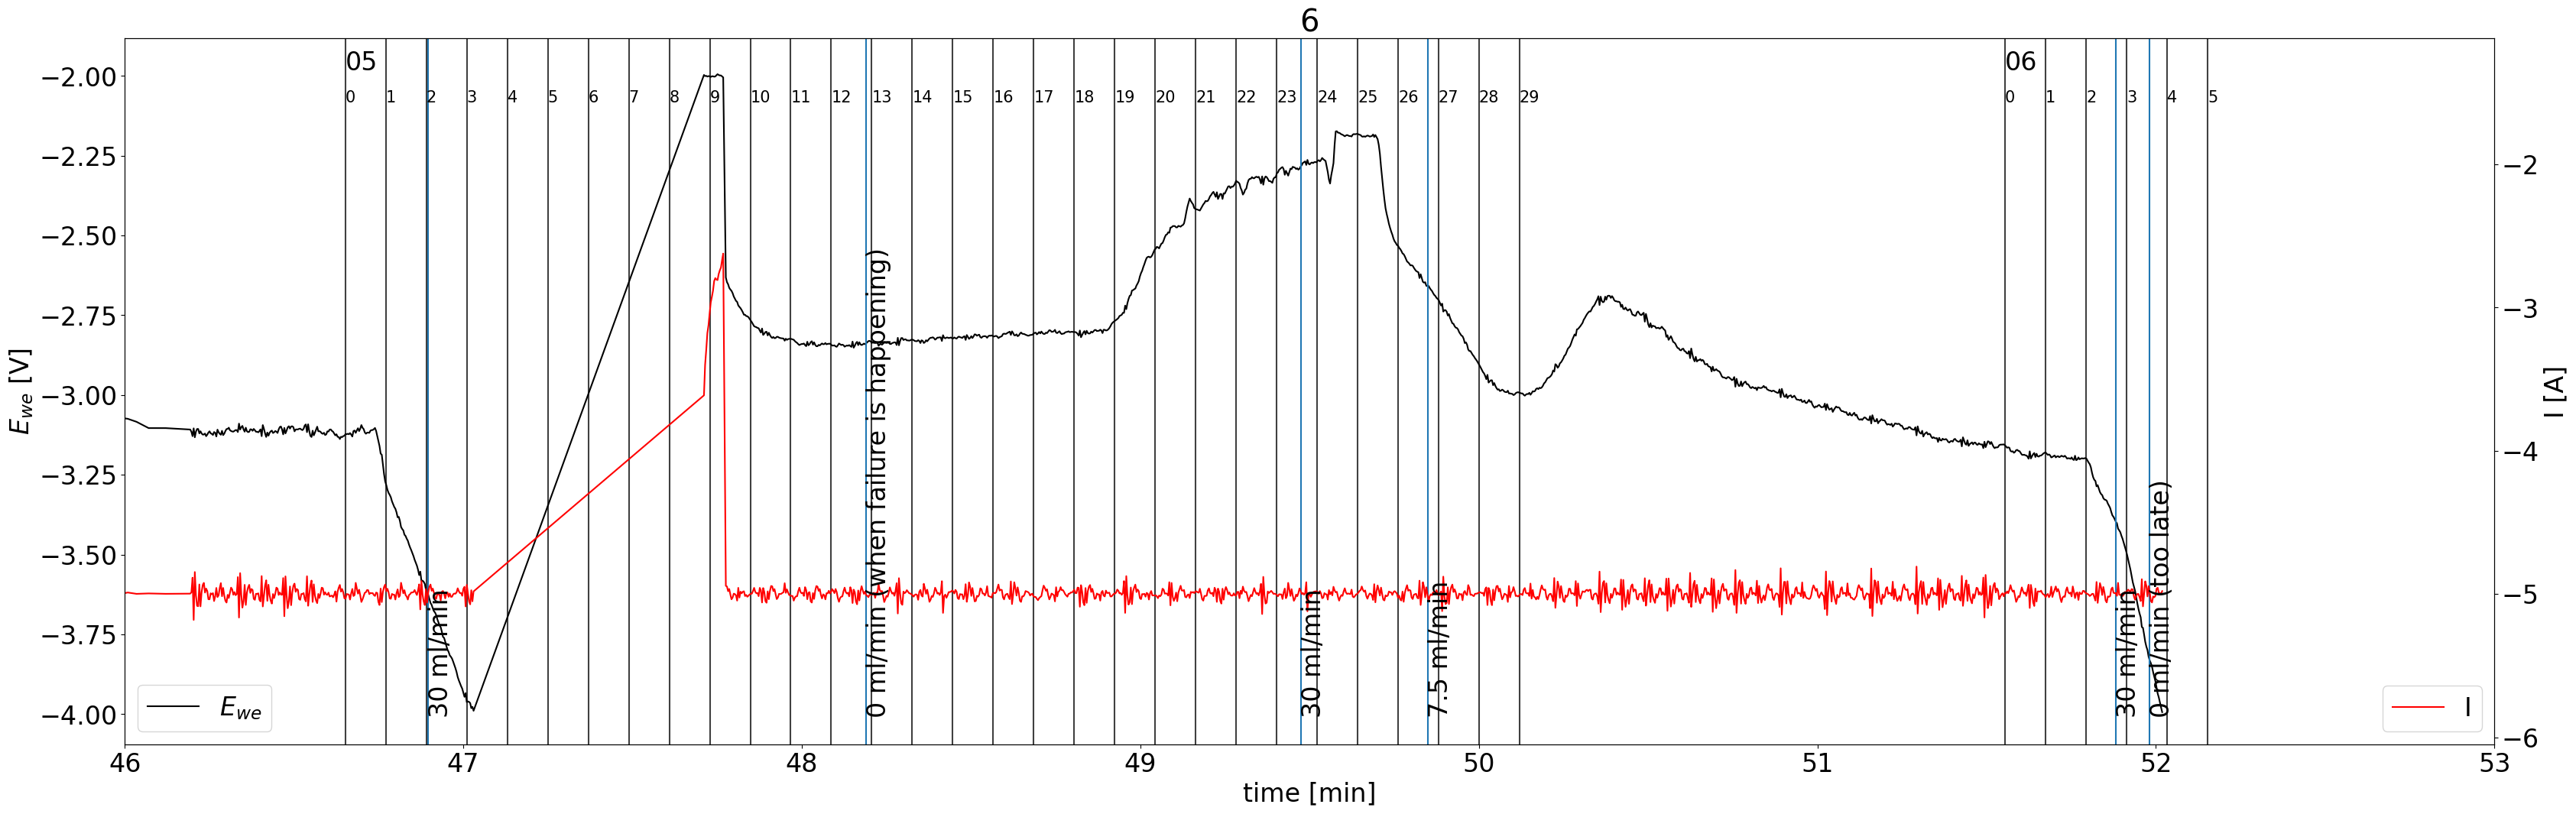

In [15]:
plot_EC_with_annot(sample)
plot_EC_with_annot(sample, tl=(46,53))

## Cell 3II

### short description

Potentiostatic operation 3.5V

In [16]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

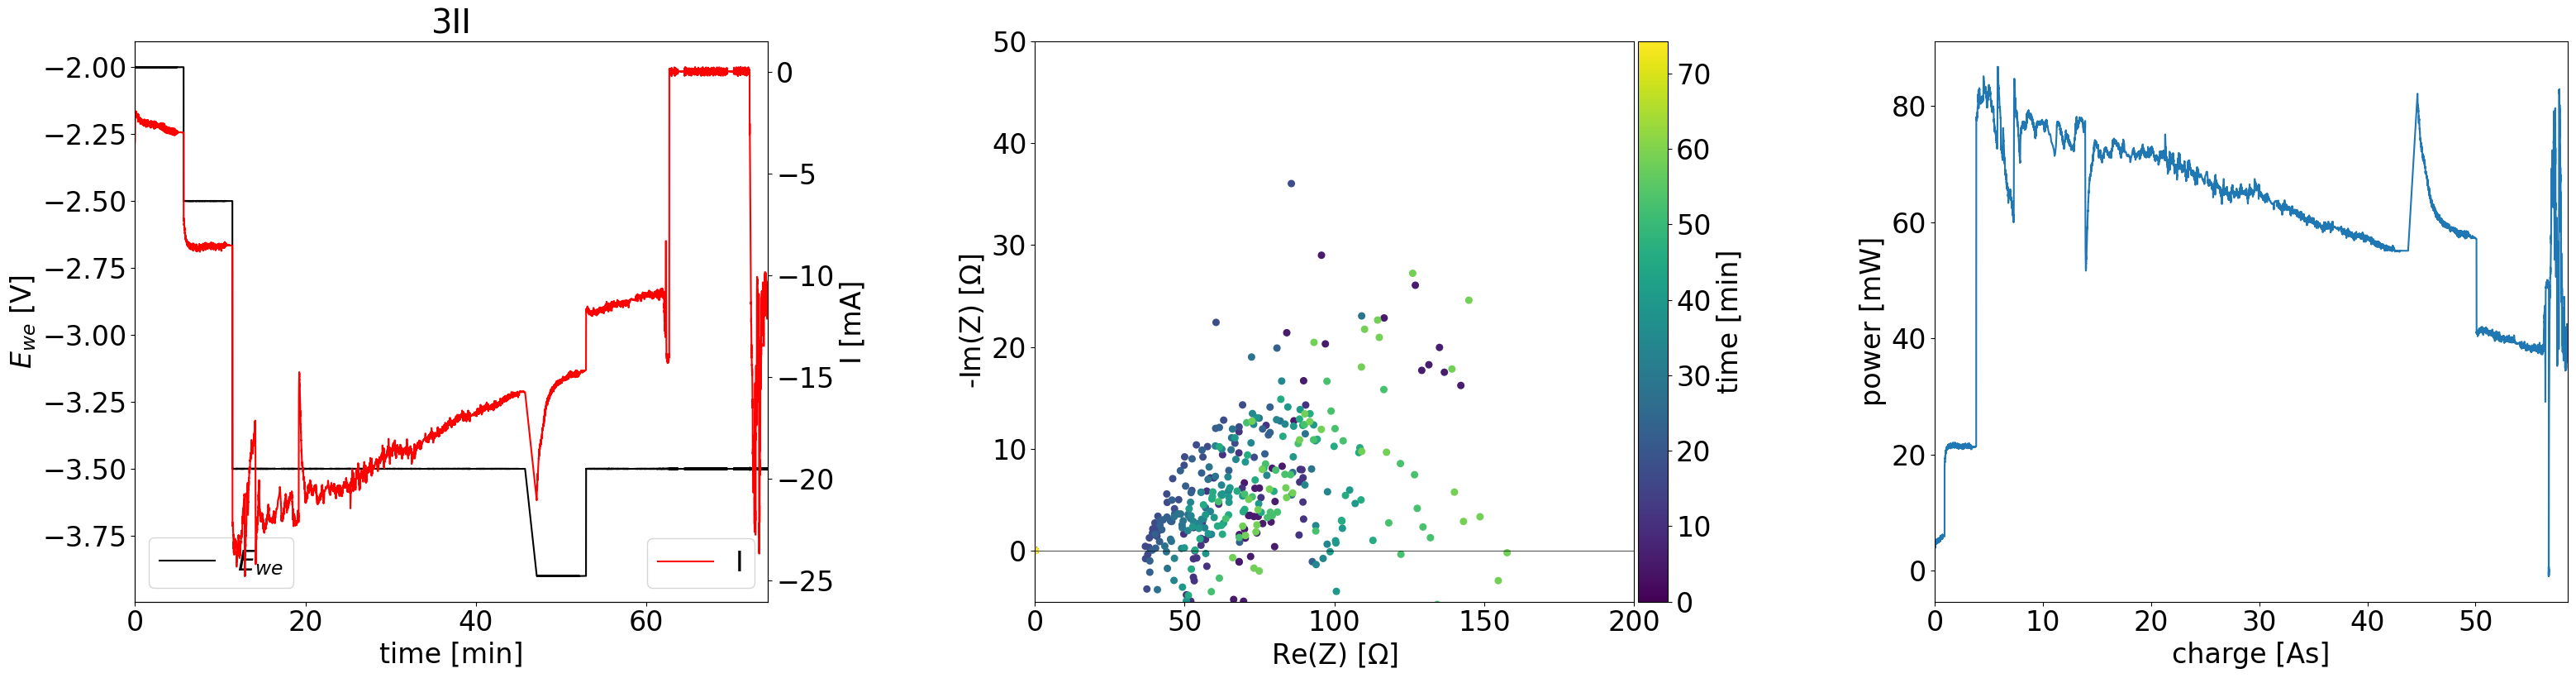

In [17]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

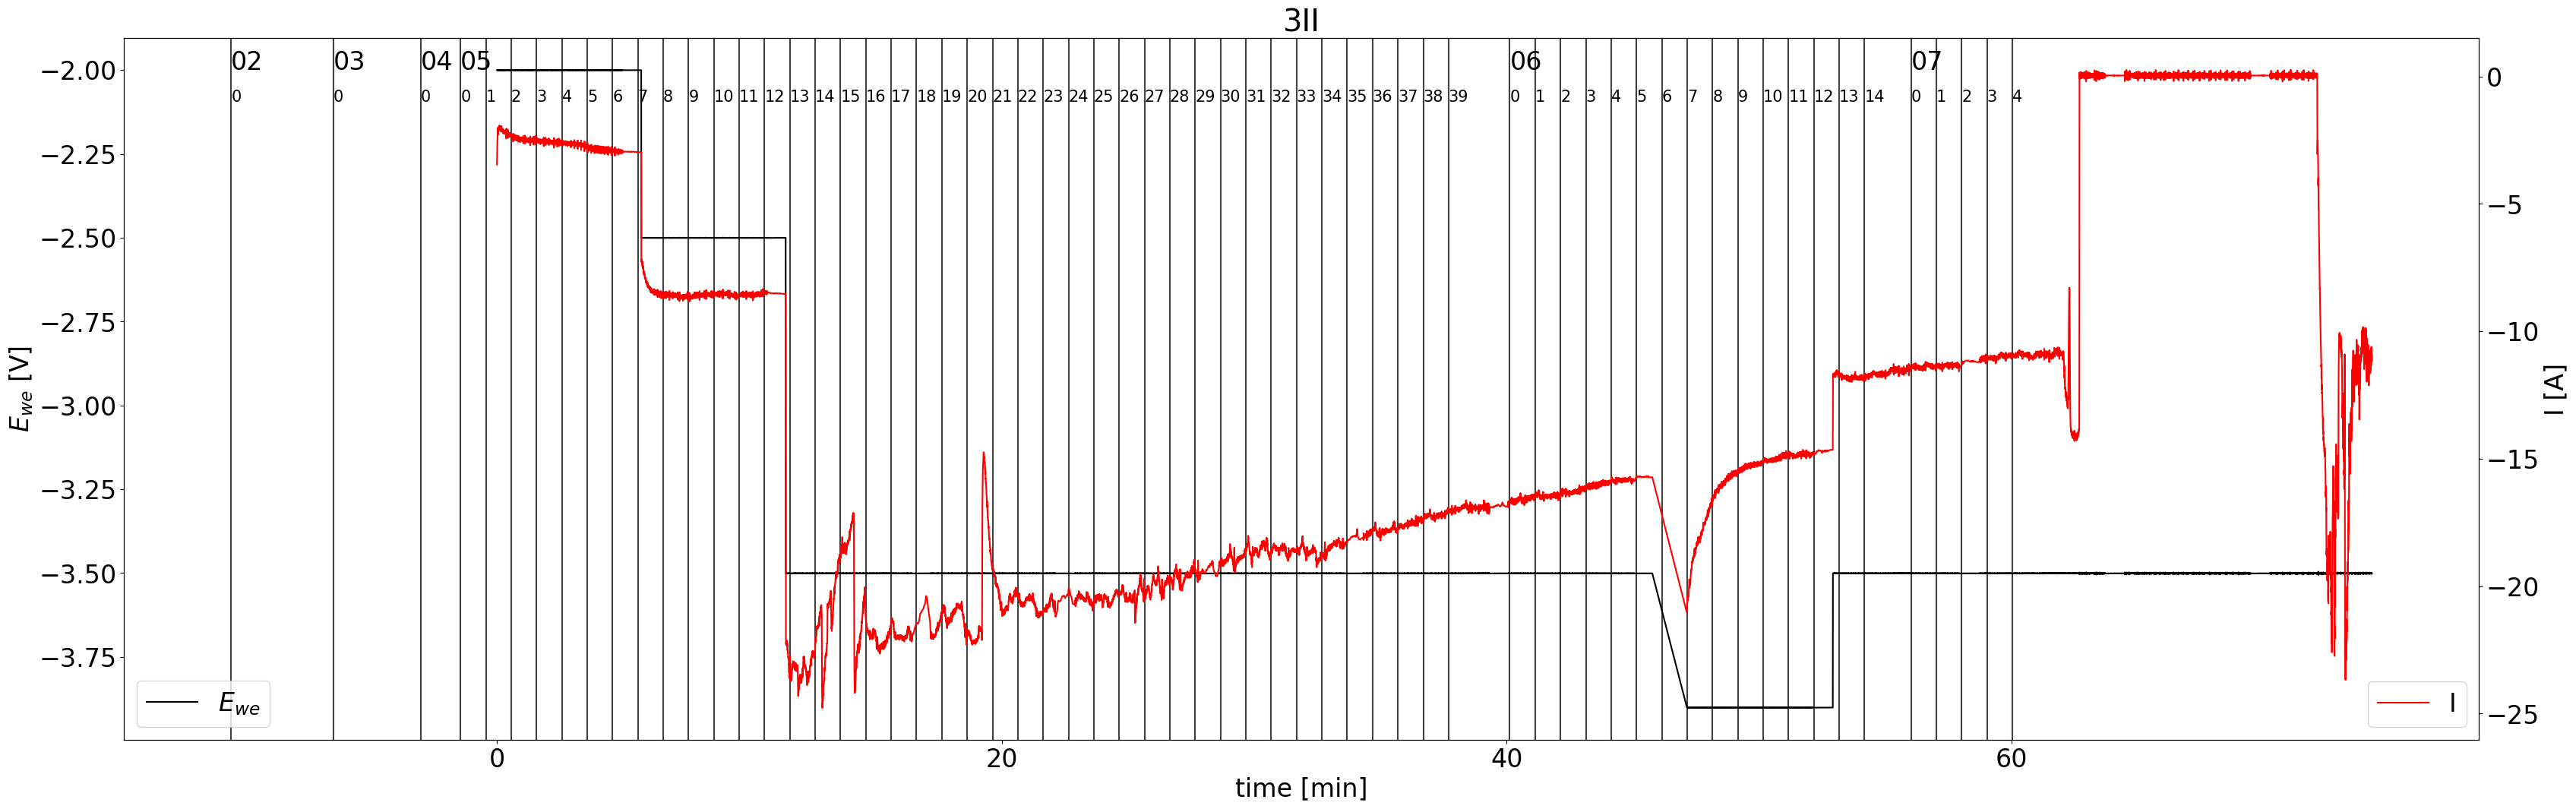

In [18]:
plot_EC_with_annot(sample)

## Cell 5II

### short description

Potentiostatic operation 3.5V

In [19]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

### EC overview

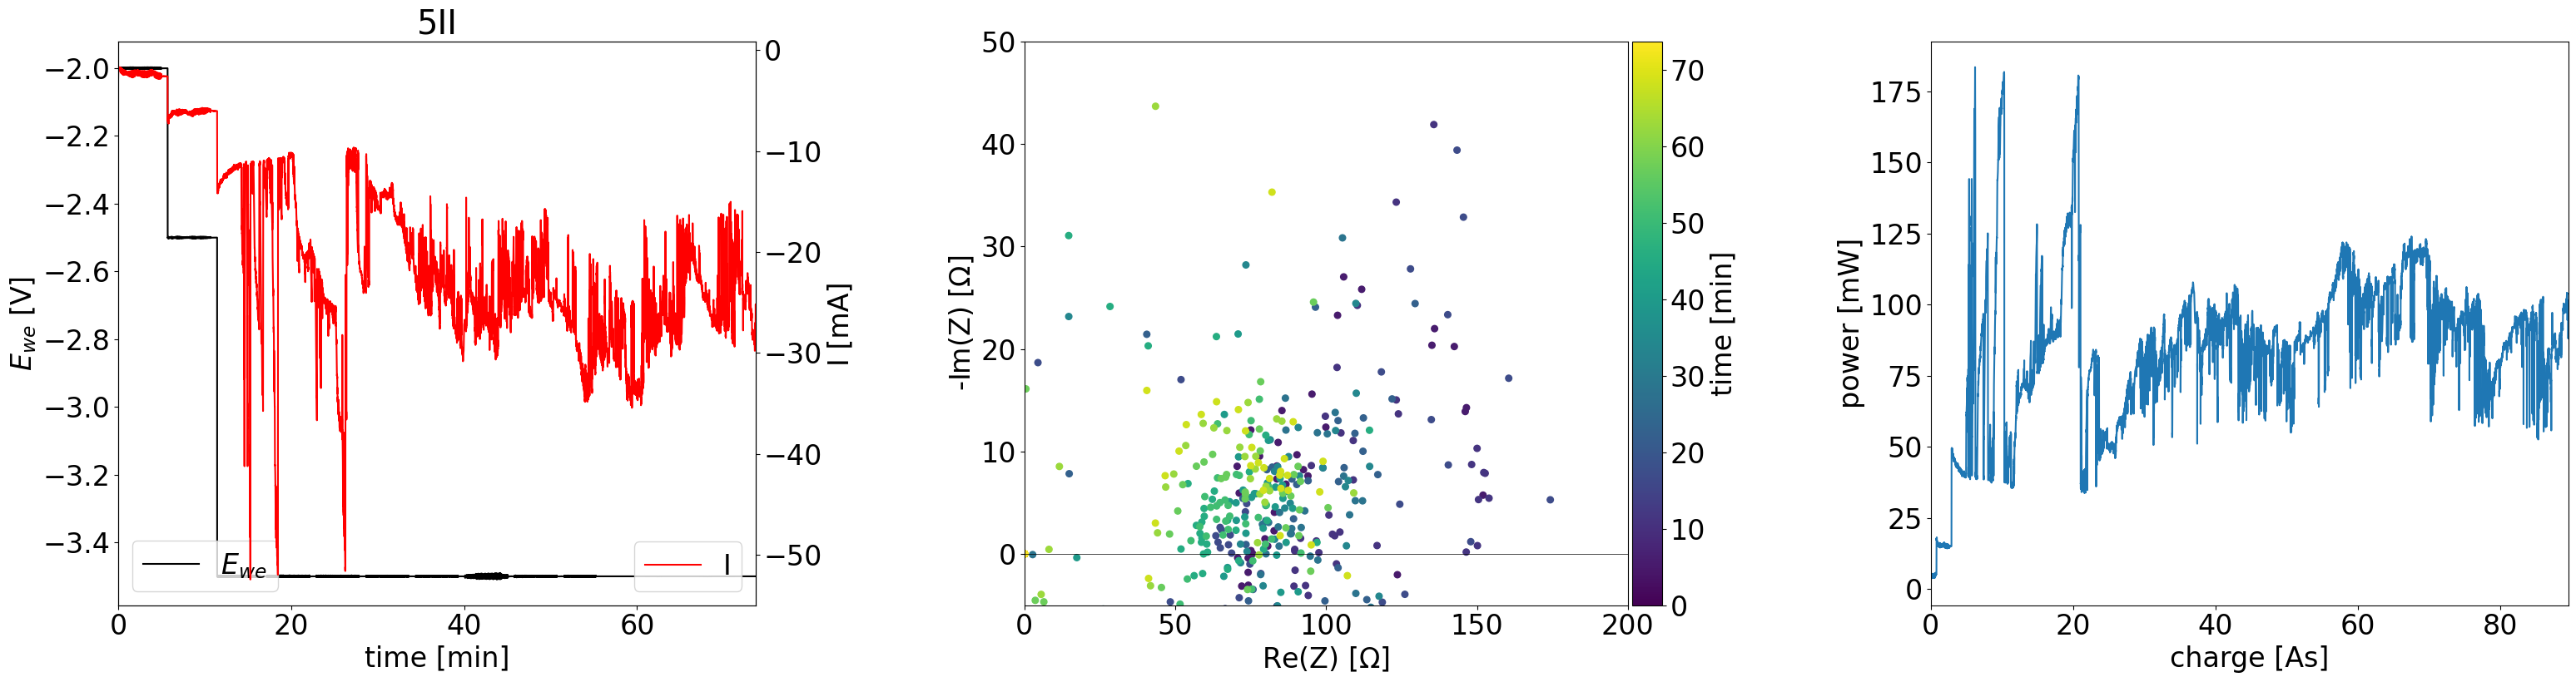

In [20]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

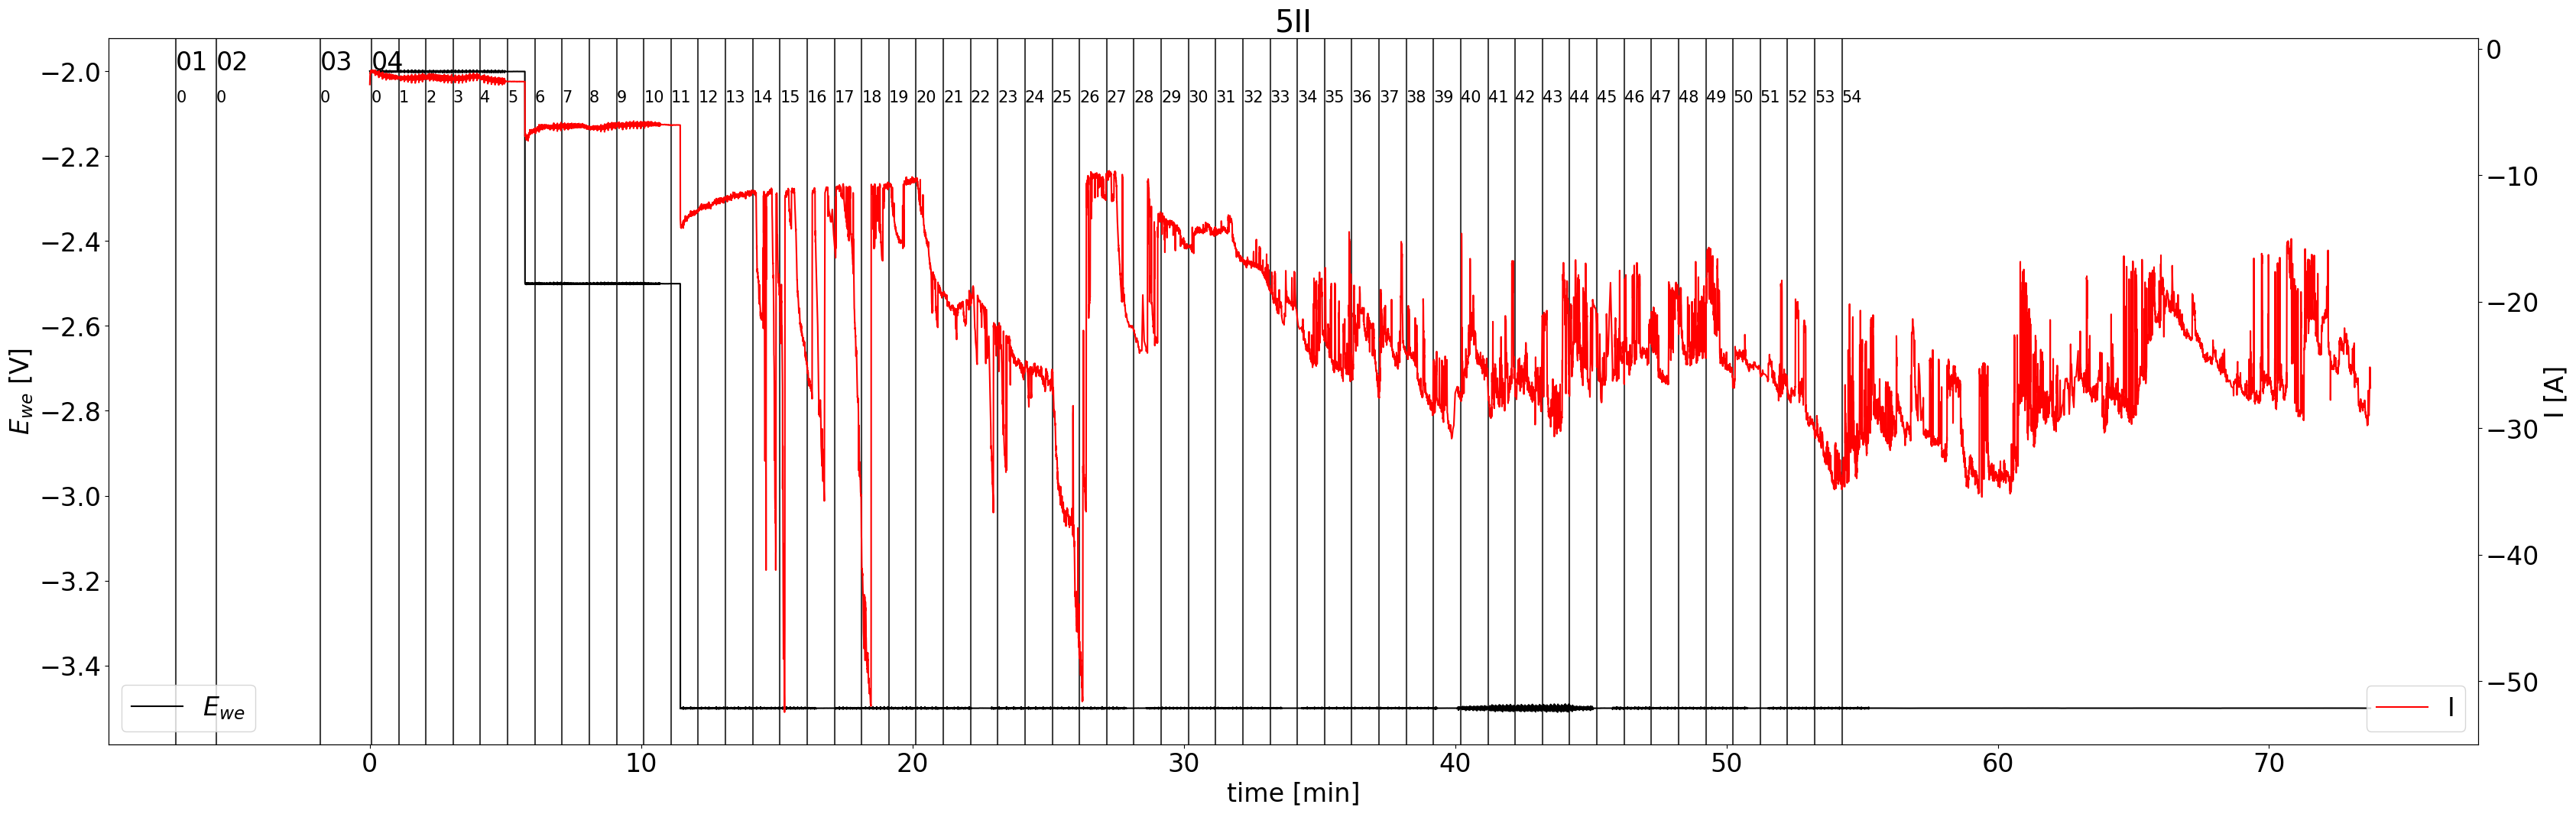

In [21]:
plot_EC_with_annot(sample)

## Cell 4II

### short description

current rampup <br />
potential safety limit overflow -> filter extreme E values

In [22]:
# load data TODO wrap into function and provided small dossier as dict
sample = '4II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

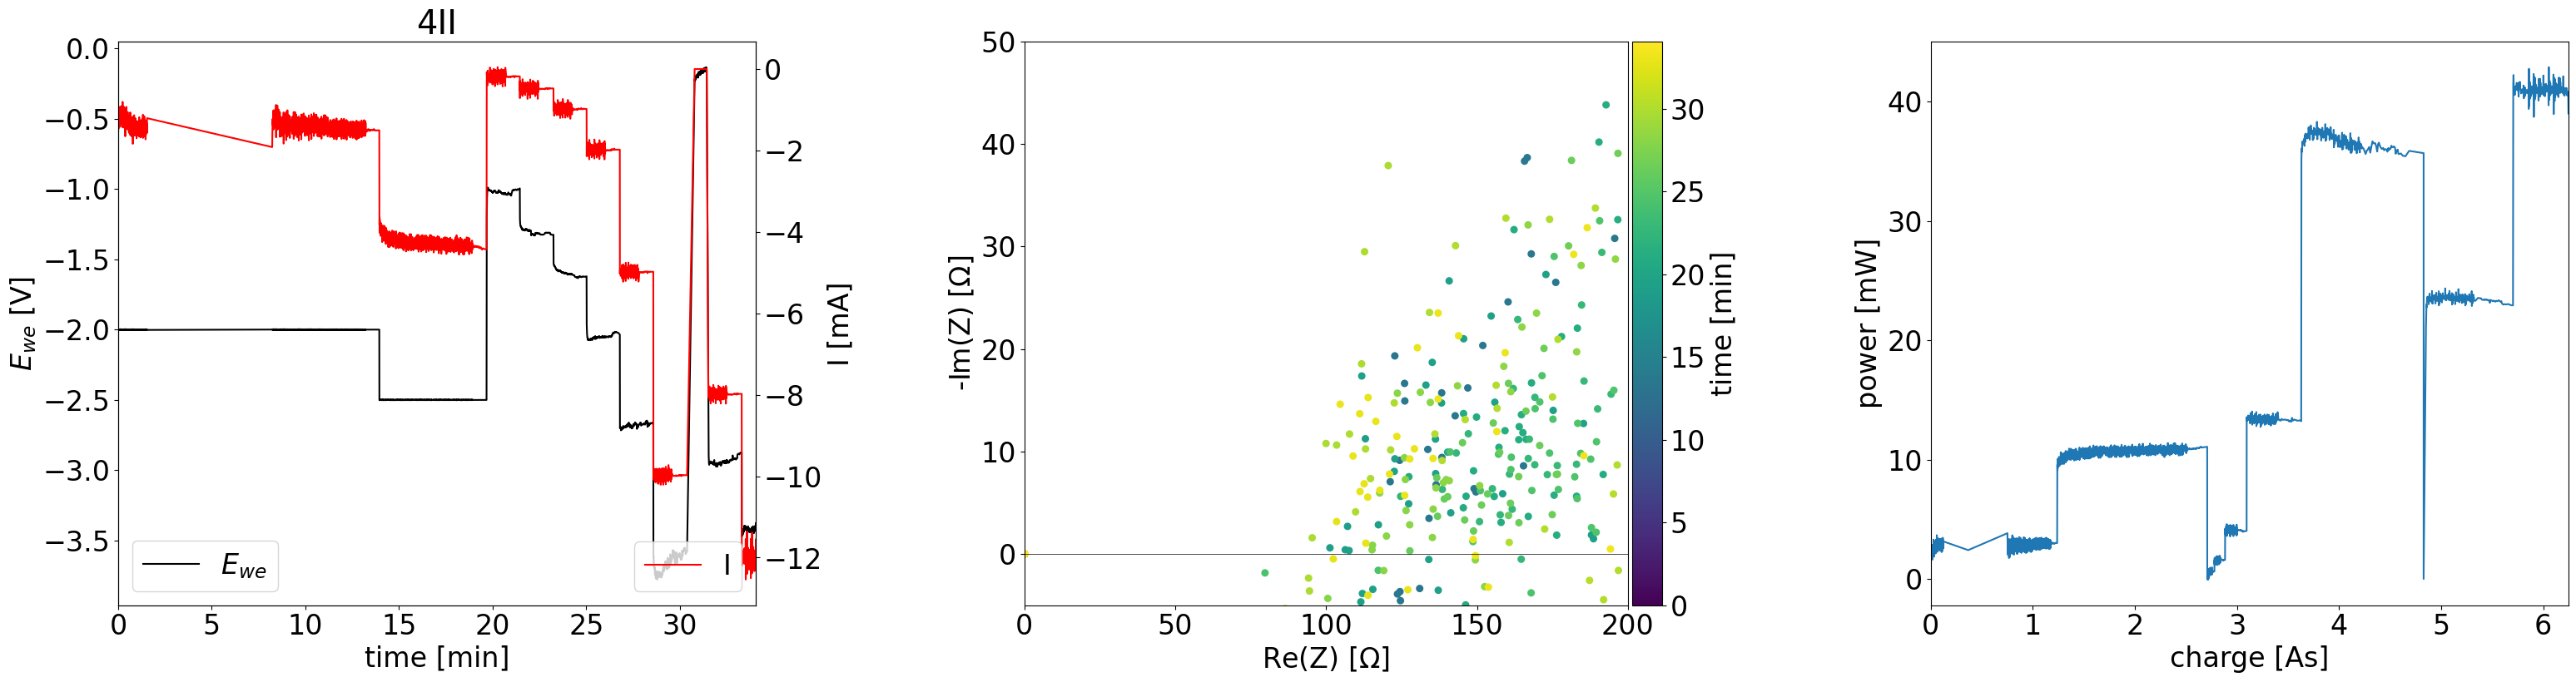

In [23]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

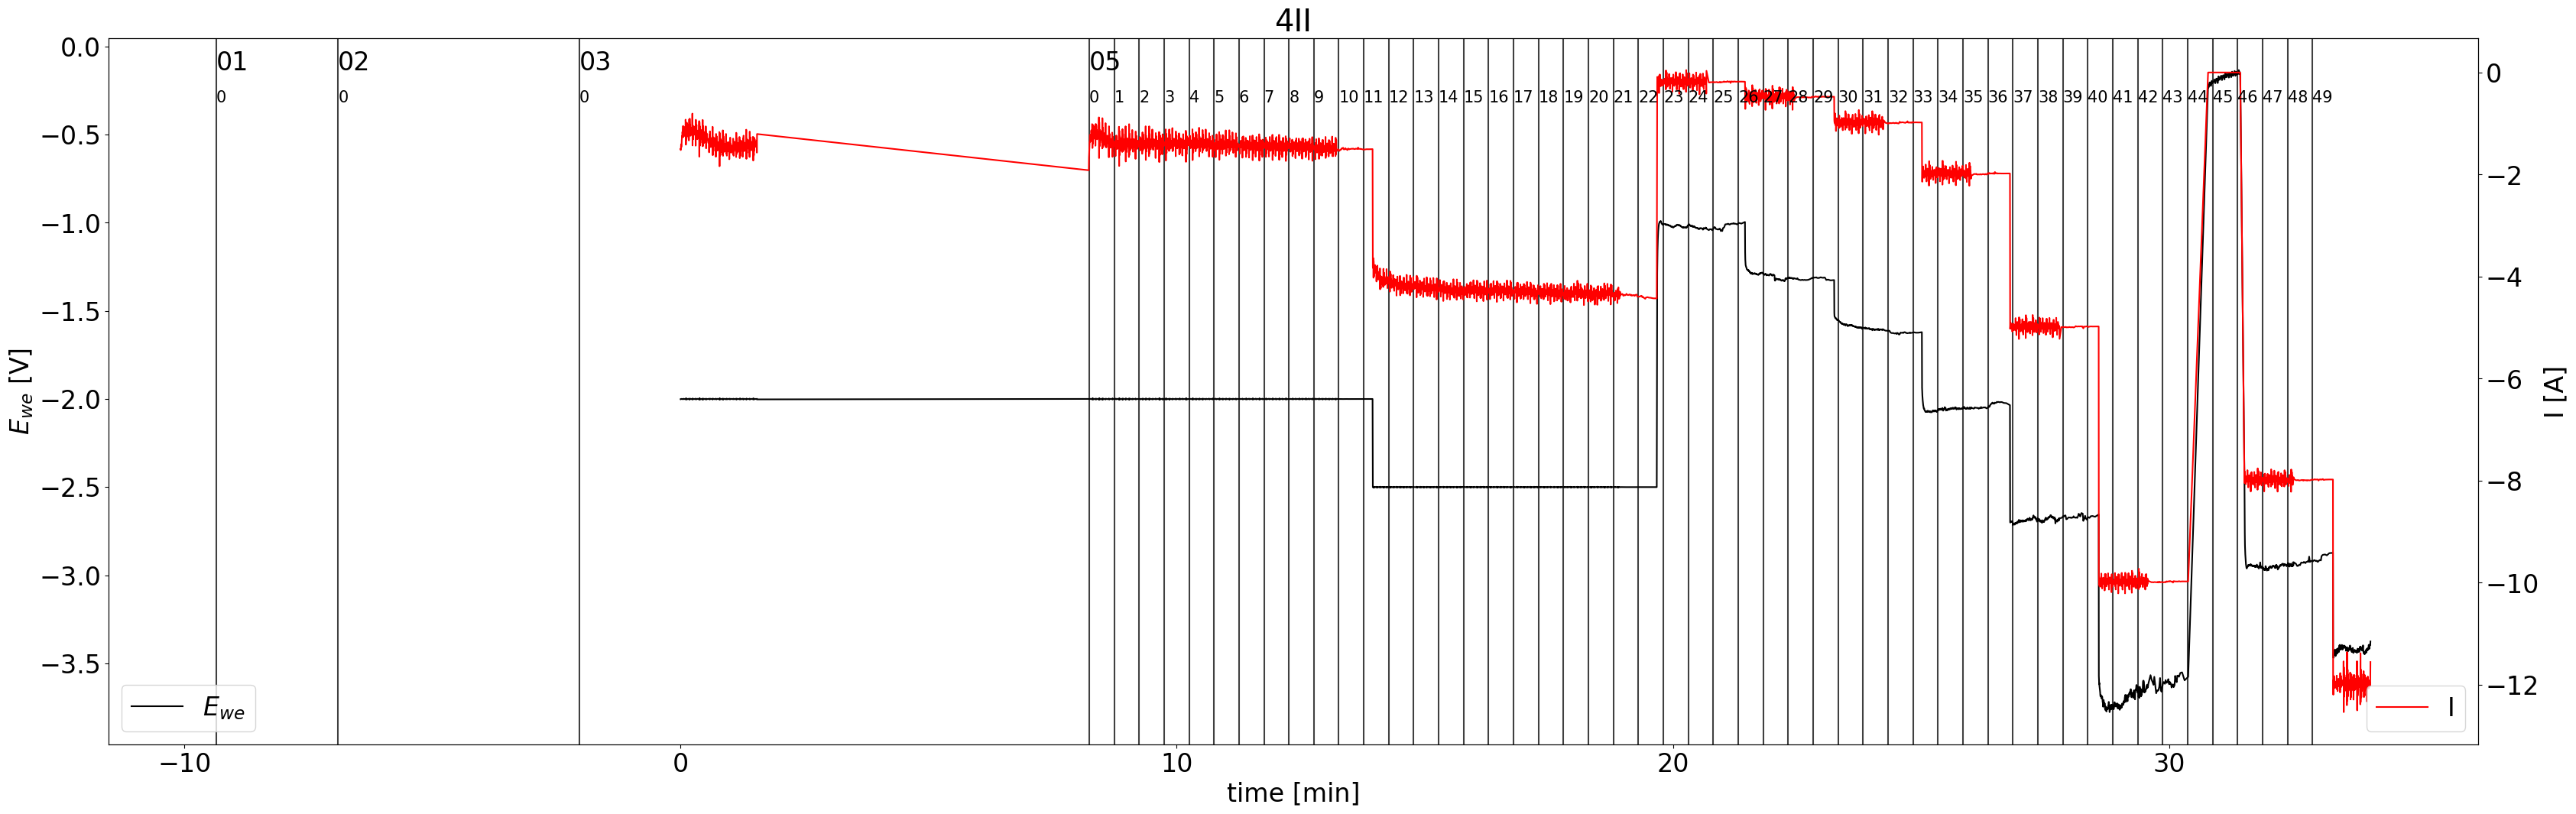

In [24]:
plot_EC_with_annot(sample)

## Cell 8x

### short description

current rampup <br />

In [25]:
# load data TODO wrap into function and provided small dossier as dict
sample = '8x'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

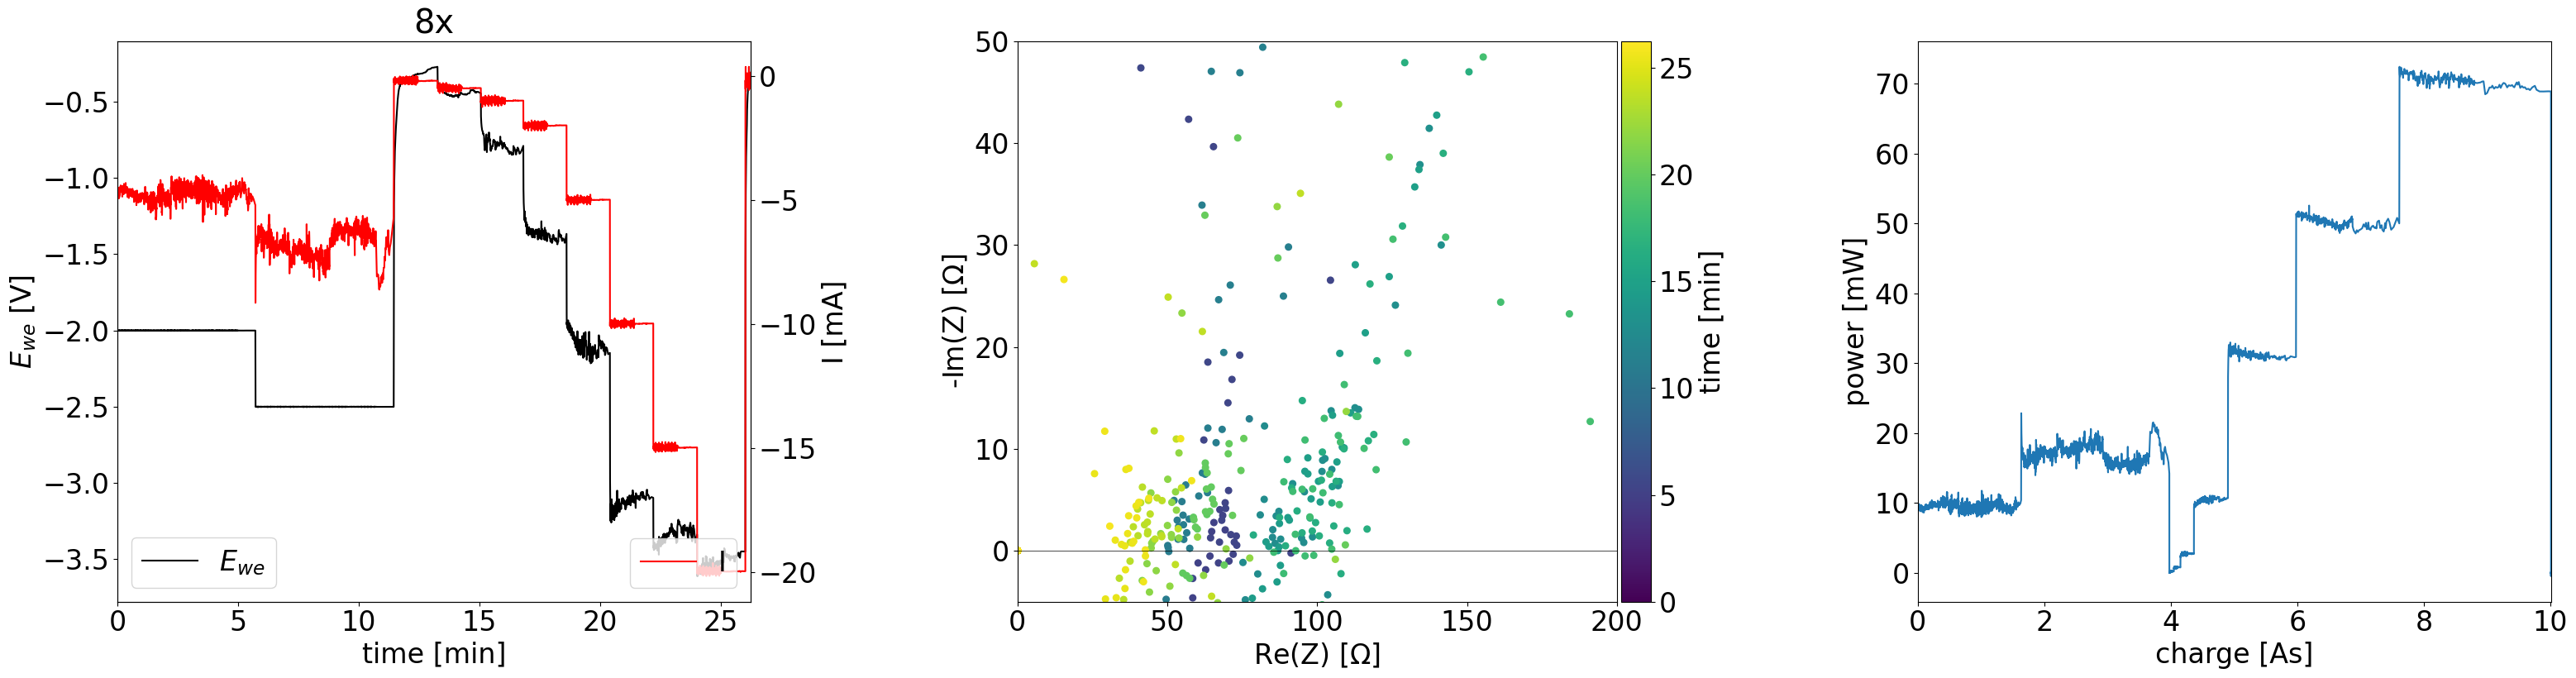

In [26]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

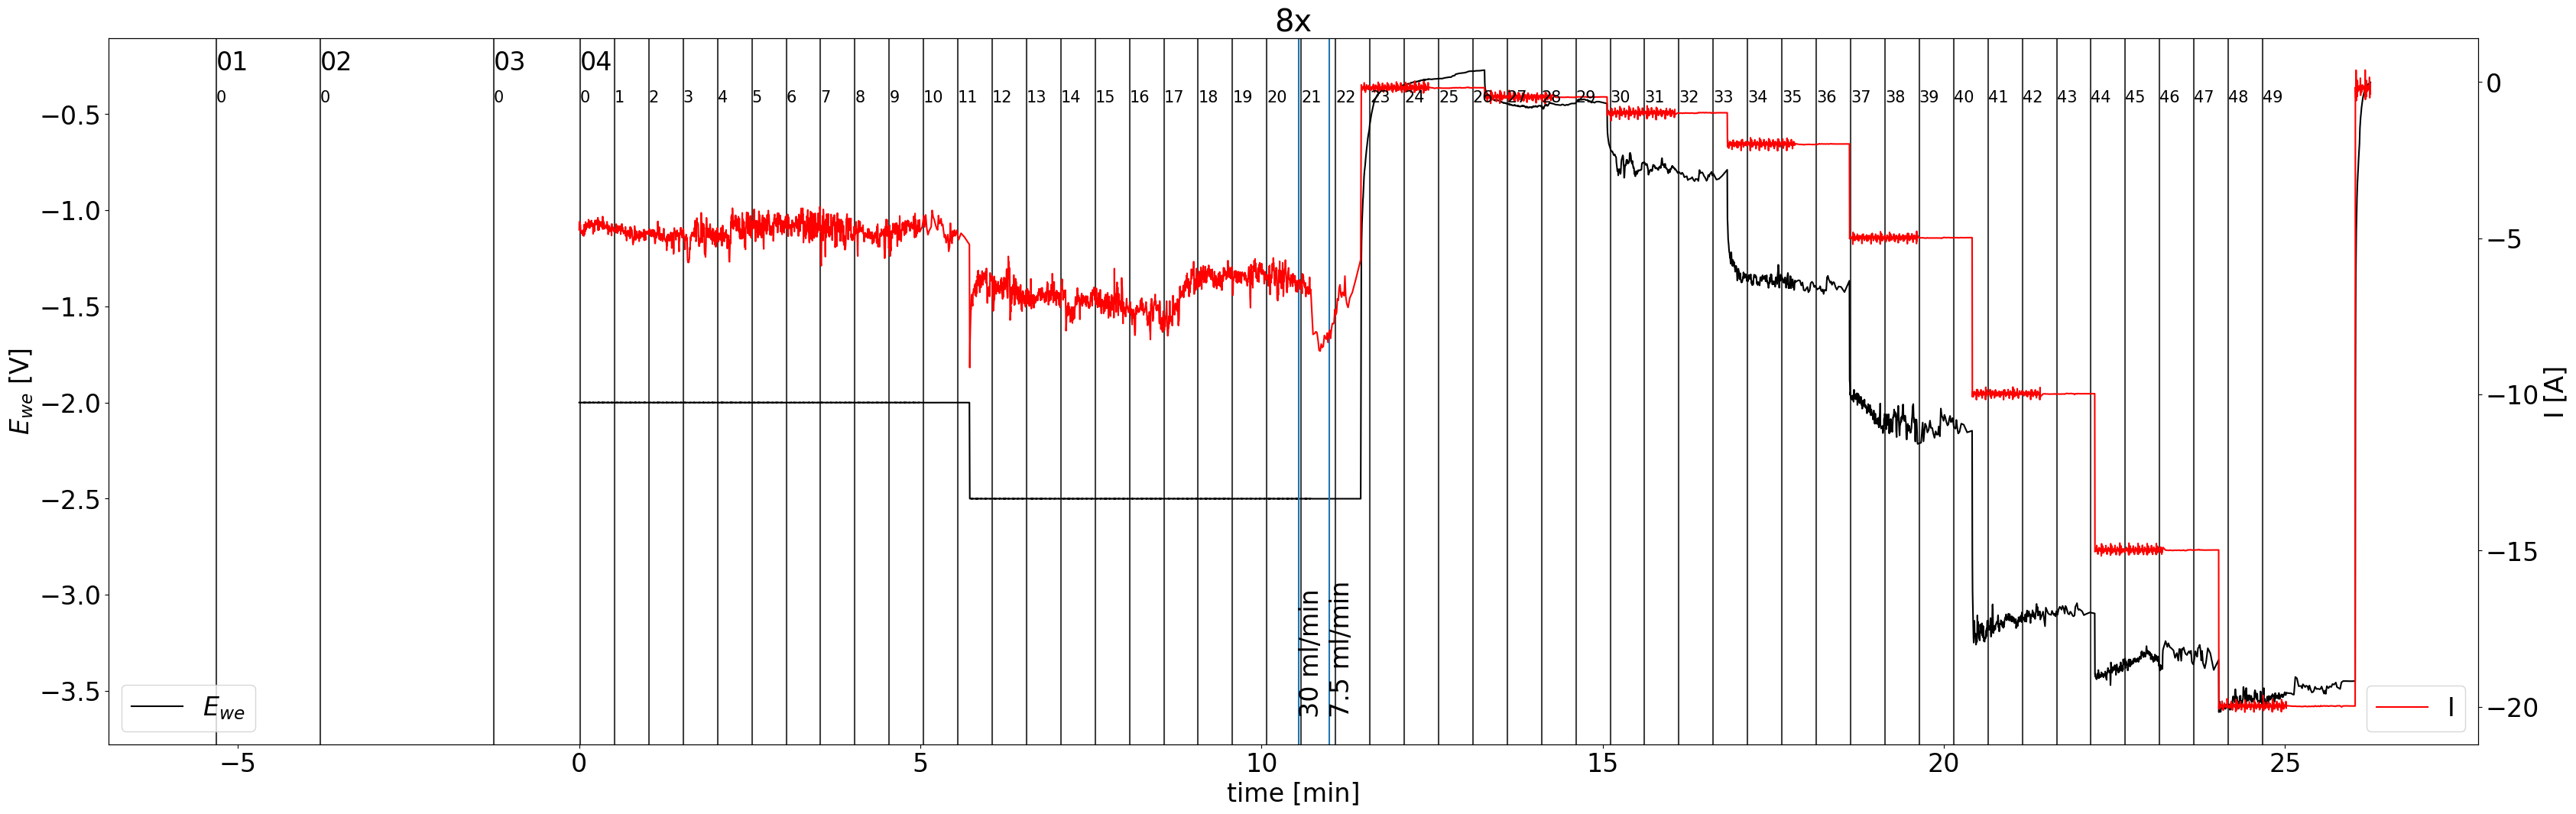

In [27]:
plot_EC_with_annot(sample)

## Cell 3III

### short description

Galvanostatic 14 mA

In [28]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3III'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

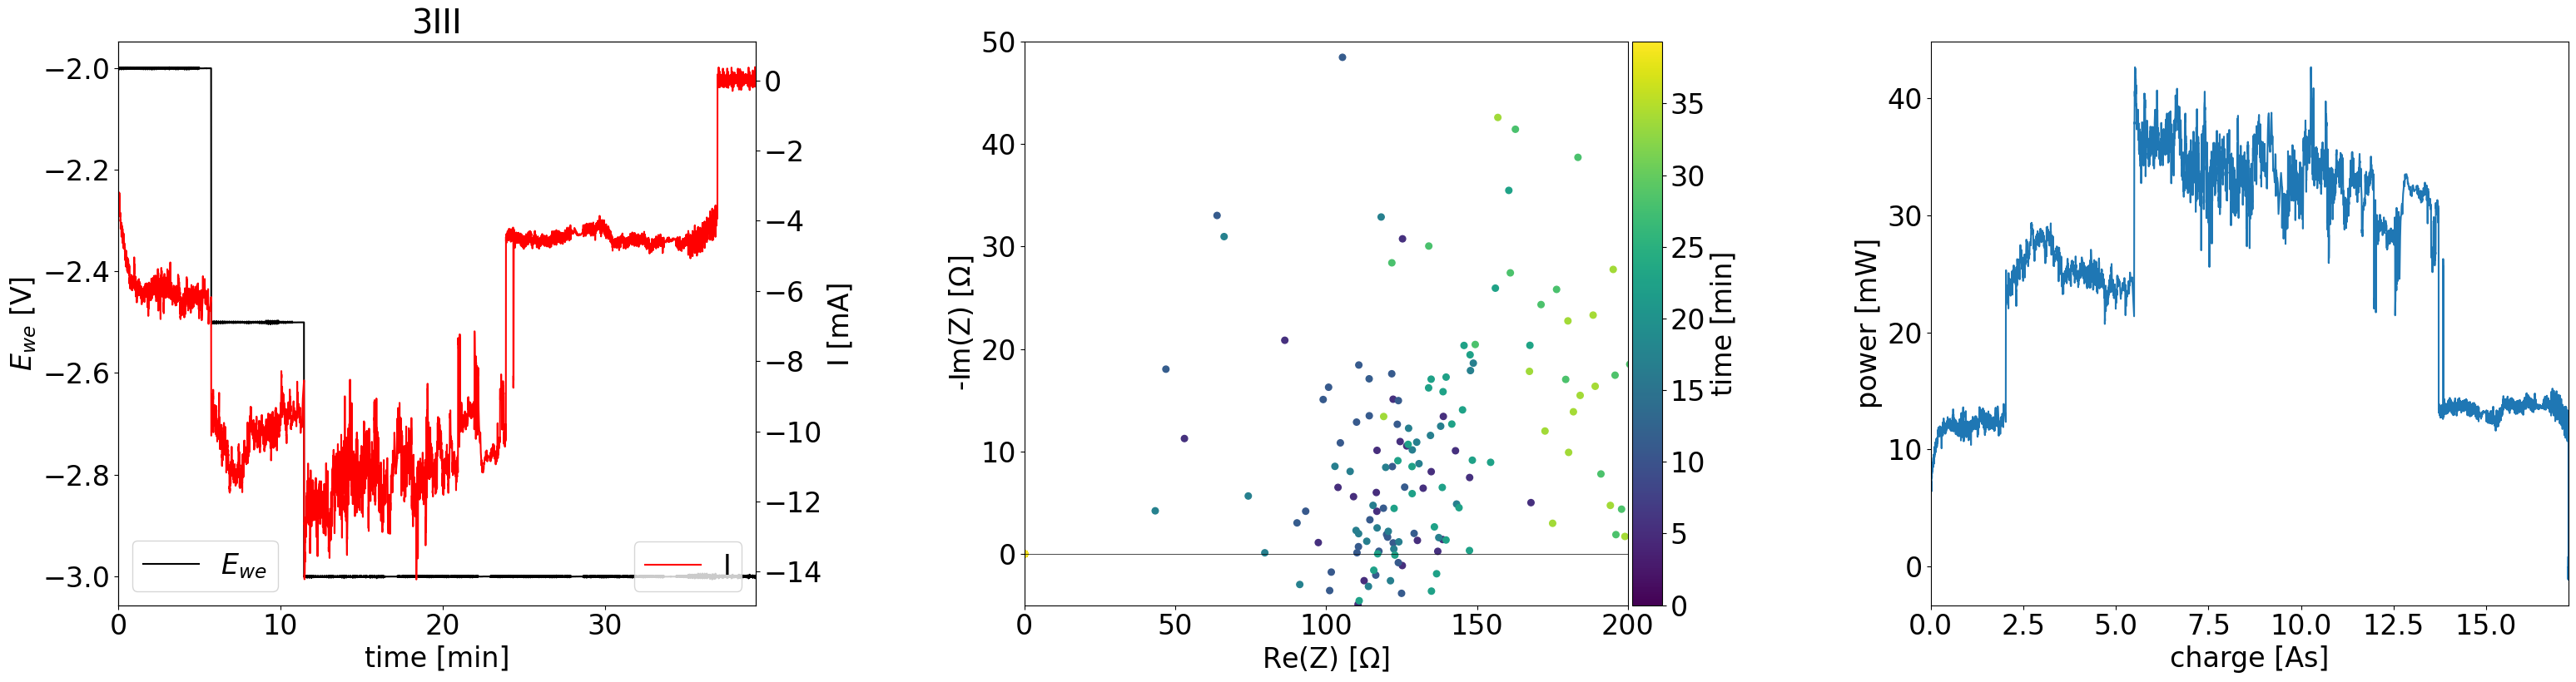

In [29]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

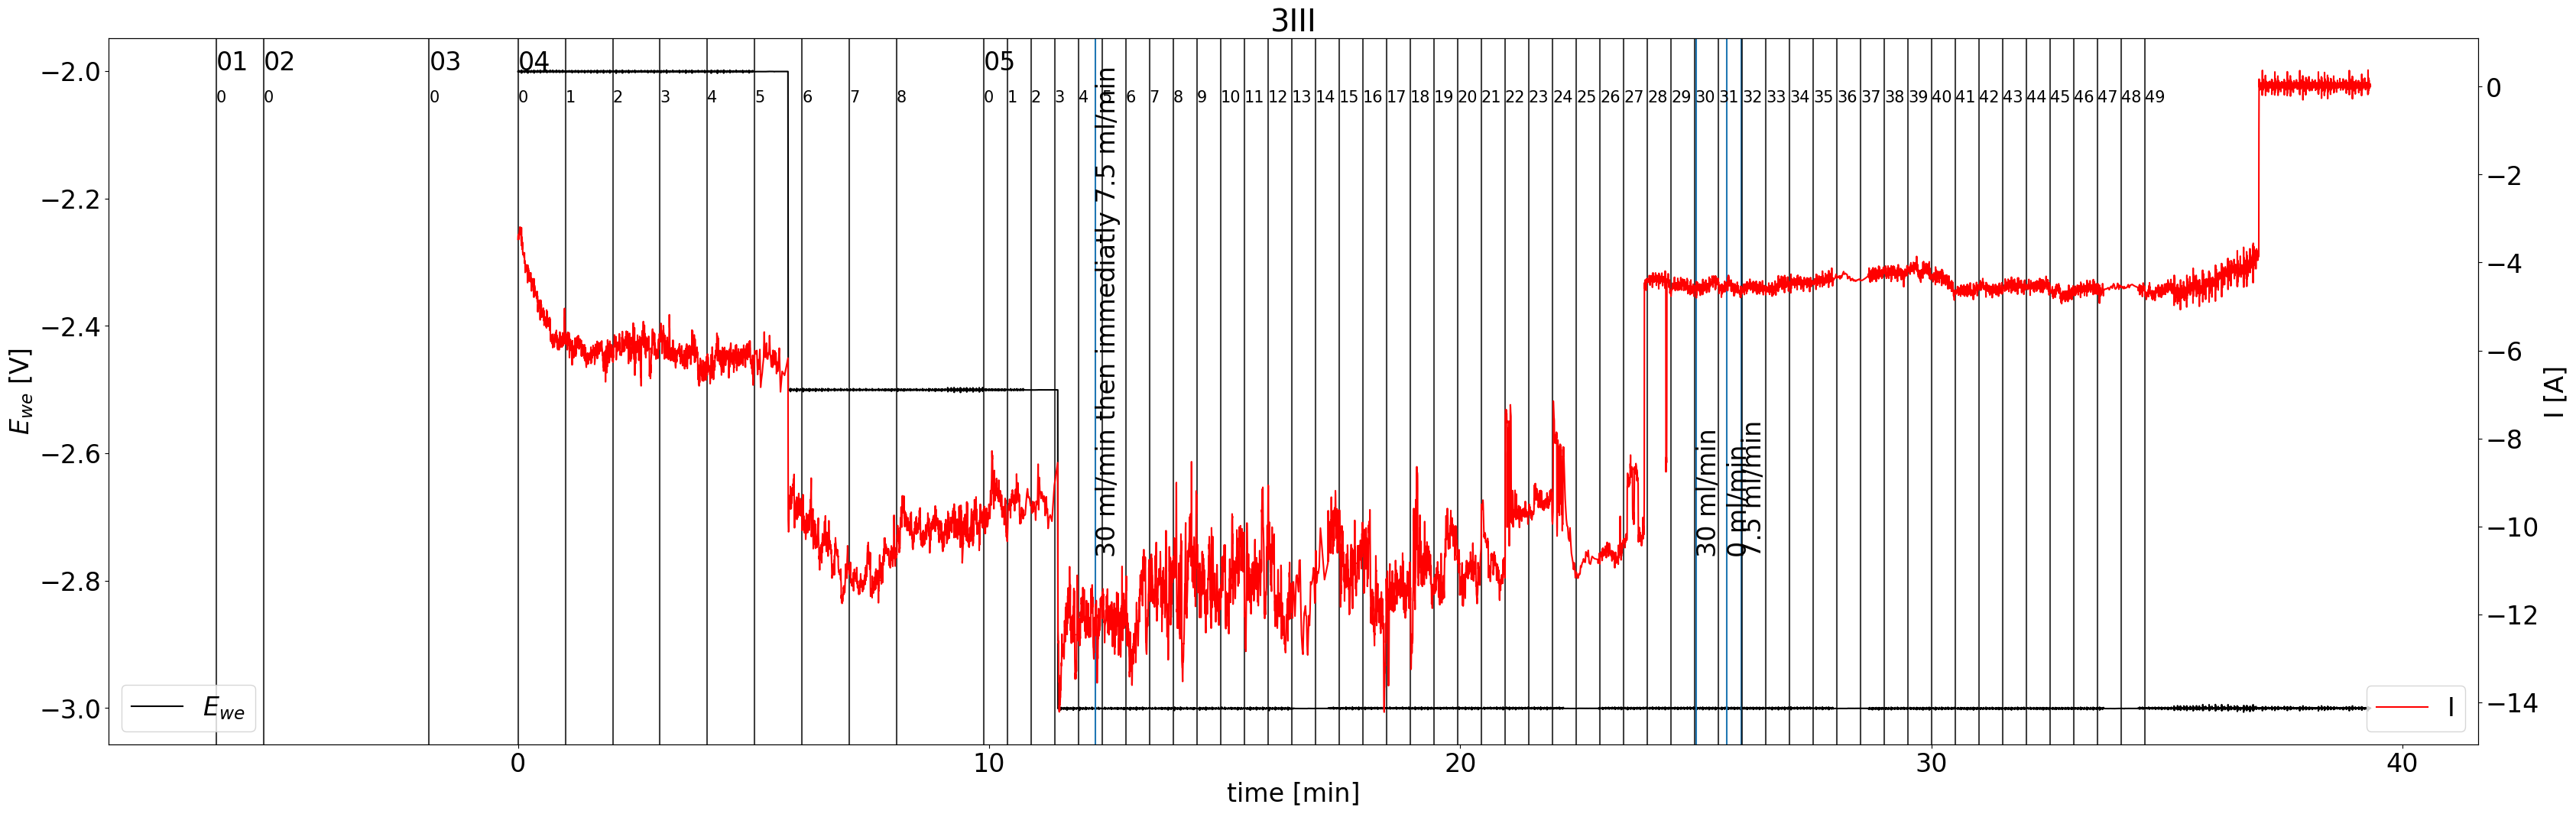

In [31]:
plot_EC_with_annot(sample, y_txt_frac=6/8)

## Cell 7x

### short description

Galvanostatic 5mA <br />
GDL with punch slits

In [32]:
# load data TODO wrap into function and provided small dossier as dict
sample = '7x'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

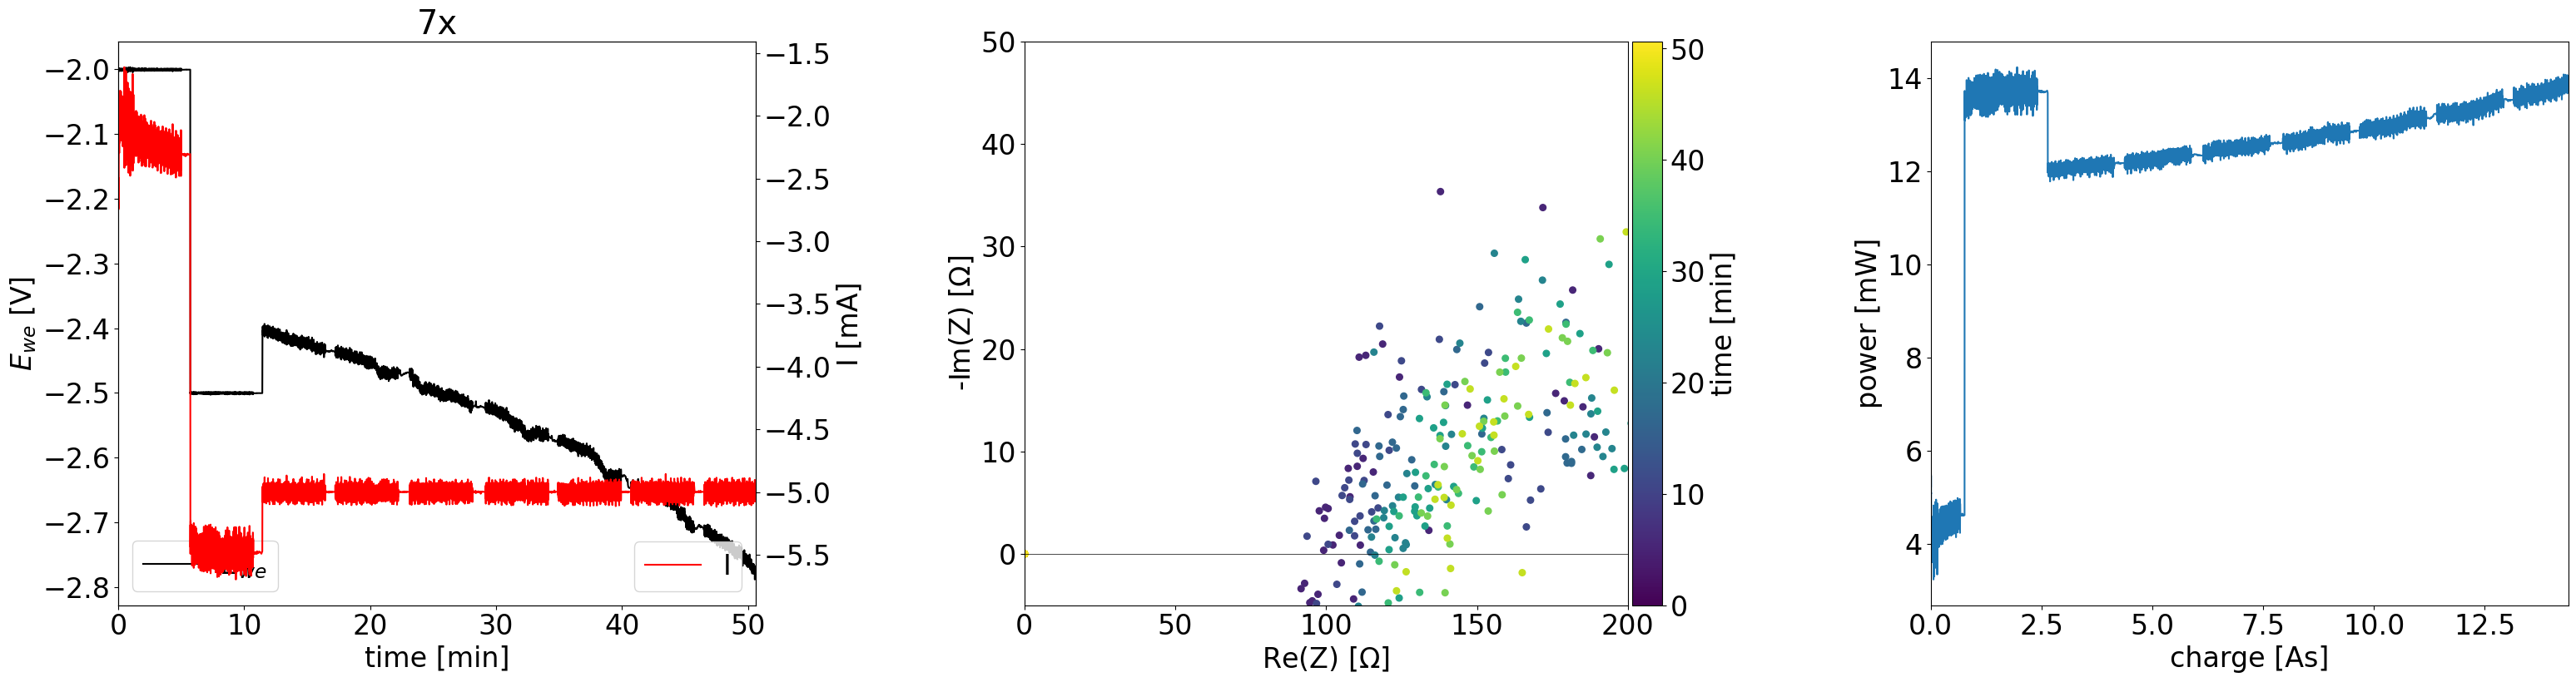

In [33]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

### EC with gas cues and XTM time steps
black vertical lines: XTM scans </br>
blue vertical lines: cues for e.g. changes in gas flow

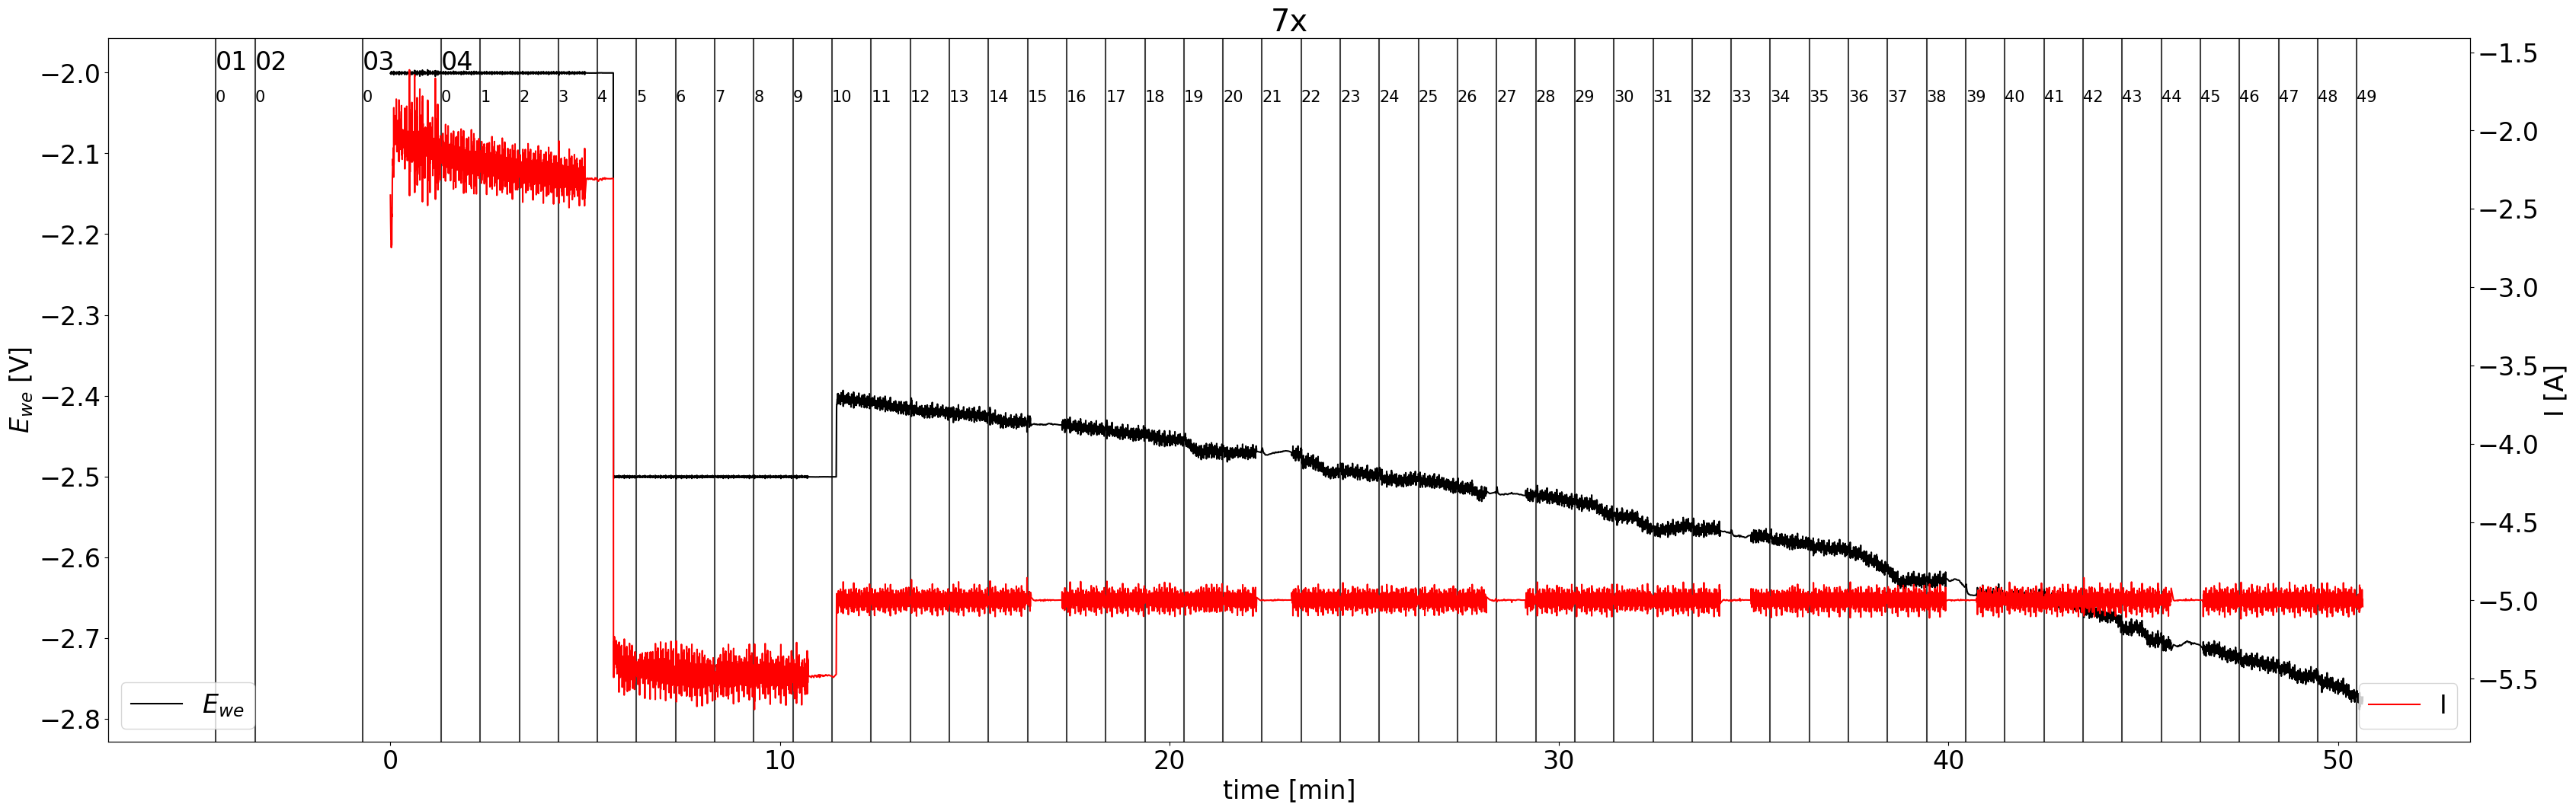

In [34]:
plot_EC_with_annot(sample)